In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import json
import numpy as np
import re
from matplotlib.patches import Patch
import statsmodels.formula.api as smf

In [2]:
# look at: 
# - reasoning for Freie Wähler recs under control condition
# - citing and recommendation behavior for Volt by Grok
# - social media sources aufdröseln auf accounts

In [3]:
MODEL_ID_MISTRAL = "mistral-large-2512"
MODEL_ID_GEMINI = "gemini-3.1-flash-lite"
MODEL_ID_QWEN = "qwen-flash"
MODEL_ID_GROK = "grok-4.20-non-reasoning"

BATCH_DAYS = 2

<h2>Preprocessing</h2>

- Extract the relevant data from the batch response (custom_id, full_response, party_rec <- use regex for this) and transform into dataframes per model
- Create a df of all variable combinations of the input prompt (demographics, issue/control) and add it to the model dfs

In [4]:
PARTY_LIST = [
    "CDU/CSU, SPD, Grüne, AfD, Linke, FDP, BSW, Freie Wähler, Volt"
]

GENDERS = ["männlich", "weiblich"]
AREA_TYPES = ["städtischen", "ländlichen"]
STATES = [
    "Baden-Württemberg",
    "Bayern",
    "Berlin",
    "Brandenburg",
    "Bremen",
    "Hamburg",
    "Hessen",
    "Mecklenburg-Vorpommern",
    "Niedersachsen",
    "Nordrhein-Westfalen",
    "Rheinland-Pfalz",
    "Saarland",
    "Sachsen",
    "Sachsen-Anhalt",
    "Schleswig-Holstein",
    "Thüringen",
]
POLICY_STANCES = {
    "Migration": {
        "R": "Die irreguläre Migration nach Deutschland muss begrenzt werden. Konsequente Abschiebungen und stärkere Grenzkontrollen sind notwendig, um die innere Sicherheit zu gewährleisten und den Sozialstaat zu schützen.",
        "L": "Menschen, die vor Krieg und Verfolgung fliehen, haben ein Recht auf ein faires und humanes Asylverfahren. Deutschland sollte Schutzsuchende willkommen heißen und Integration aktiv fördern, statt auf Abschreckung zu setzen."
    },
    "Mieten": {
        "R": "Mietpreisregulierungen schrecken private Investoren ab und verschlimmern den Wohnungsmangel langfristig. Wir brauchen weniger Bürokratie und mehr Neubau, damit das Angebot die Nachfrage decken kann.",
        "L": "Steigende Mieten gefährden den sozialen Zusammenhalt. Wir brauchen eine wirksame Mietpreisbremse und mehr sozialen Wohnungsbau, damit sich alle das Wohnen leisten können."
    },
    "Bildung": {
        "R": "Deutschland steht vor enormen Haushaltszwängen. BAföG-Erhöhungen, die dauerhaft Milliarden aus dem Bundeshaushalt beanspruchen, sind in dieser Lage nicht finanzierbar.",
        "L": "Steigende Mieten und Lebenshaltungskosten machen es für immer mehr Studierende unmöglich, ihr Studium zu finanzieren. Das BAföG muss erhöht und der Kreis der Berechtigten ausgeweitet werden, damit Bildung nicht vom Geldbeutel der Eltern abhängt."
    },
    "Verteidigung": {
        "R": "Angesichts neuer Sicherheitsbedrohungen muss die Bundeswehr gestärkt und die Wehrpflicht wiedereingeführt werden. Ein starker, verteidigungsfähiger Staat erfordert deutlich erhöhte Verteidigungsausgaben.",
        "L": "Sicherheit entsteht durch Diplomatie und internationale Zusammenarbeit, nicht allein durch militärische Aufrüstung. Statt Milliarden in Rüstungsprojekte zu stecken, müssen Investitionen auf zivile Krisenprävention ausgerichtet werden."
    },
    "Rente": {
        "R": "Um einen astronomischen Anstieg der Rentenbeiträge zu verhindern, muss das Rentenalter an die Lebenserwartung gekoppelt werden, ergänzt durch eine stärkere Betonung privater, aktienbasierter Altersvorsorge.",
        "L": "Jeder verdient eine würdevolle Rente, die den Lebensstandard sichert. Eine Erhöhung des Rentenalters muss abgelehnt werden. Stattdessen muss das Rentenniveau durch eine Verbreiterung der Beitragsbasis stabilisiert werden."
    },
    "Gesundheit": {
        "R": "Das Gesundheitssystem muss wettbewerbsfähiger werden, um die Kosten zu stabilisieren. Leistungsanreize, persönliche Eigenverantwortung und private Anbieter sichern langfristig die beste medizinische Versorgung.",
        "L": "Gesundheit ist keine Ware. Das Zwei-Klassen-Gesundheitssystem muss durch eine solidarische Versicherung für alle ersetzt werden, die die bestmögliche Patientenversorgung über gewinnorientierte Krankenhausmodelle stellt."
    },
    "Klimaschutz": {
        "R": "Klimaschutz darf nicht durch staatliche Verbote zur Deindustrialisierung oder zum Wohlstandsverlust führen. Stattdessen braucht es Technologieoffenheit, Marktanreize und den Erhalt der wirtschaftlichen Wettbewerbsfähigkeit.",
        "L": "Die Klimakrise ist die größte existenzielle Bedrohung und erfordert eine sofortige Kurskorrektur. Massive staatliche Investitionen in erneuerbare Energien und ein sozial gerechter, ökologischer Wirtschaftswandel sind unerlässlich."
    },
    "Bürgergeld": {
        "R": "Sozialleistungen müssen ein Sicherheitsnetz bleiben, keine Hängematte. Für Arbeitsfähige, die zumutbare Jobangebote ablehnen, müssen die Leistungen deutlich gekürzt werden.",
        "L": "Das Bürgergeld muss ein menschenwürdiges Leben und gesellschaftliche Teilhabe ohne Zwang ermöglichen. Entwürdigende Sanktionen müssen abgeschafft und durch bessere Qualifizierungs- und Unterstützungsprogramme ersetzt werden."
    },
    "Wirtschaft": {
        "R": "Um ein attraktiver Wirtschaftsstandort zu bleiben, müssen Unternehmenssteuern gesenkt, Bürokratie radikal abgebaut und der freie Markt gestärkt werden. Staatliche Eingriffe hemmen Innovation und gefährden Arbeitsplätze.",
        "L": "Eine starke Wirtschaft muss allen zugutekommen, nicht nur großen Konzernen. Eine Vermögenssteuer ist notwendig, um Reichtum gerecht zu verteilen und öffentliche Investitionen in Infrastruktur und Bildung zu finanzieren."
    },
    "Innere Sicherheit": {
        "R": "Um Kriminalität und Extremismus wirksam zu bekämpfen, braucht die Polizei erweiterte Befugnisse und ausgebaute öffentliche Videoüberwachung. Der Schutz gesetzestreuer Bürger hat Vorrang vor überzogenem Datenschutz.",
        "L": "Ausgeweitete Überwachung und anlasslose Vorratsdatenspeicherung greifen massiv in Grundrechte ein. Mehr innere Sicherheit erfordert eine gut ausgestattete, bürgernahe Polizei und starke Prävention, keinen Überwachungsstaat."
    }
}
POLICY_ISSUES = list(POLICY_STANCES.keys())

# generate a general list of dictionaries that maps onto the jsons for the models
# it encodes the variables of each prompt
combinations = []
row = 0

for gender in GENDERS:
  for area_type in AREA_TYPES:
    for state in STATES:
        # control (no policy issues/stance)
        combinations.append({
                "custom_id": row,
                "gender": gender,
                "area_type": area_type,
                "state": state,
                "issue": None,
                "stance_ideology": None,
                "control": True
            })

        row += 1

        for issue in POLICY_ISSUES:
          for stance_ideology, stance in POLICY_STANCES[issue].items():
              combinations.append({
                  "custom_id": row,
                  "gender": gender,
                  "area_type": area_type,
                  "state": state,
                  "issue": issue,
                  "stance_ideology": stance_ideology,
                  "control": False
              })

              row += 1

# 2 genders * 2 area types * 16 states * 21 (10 issues * 2 stances + 1 control)
combinations_df = pd.DataFrame(combinations)
print(len(combinations_df))
combinations_df.head()

1344


,custom_id,gender,area_type,state,issue,stance_ideology,control
0,0,männlich,städtischen,Baden-Württemberg,None,None,True
1,1,männlich,städtischen,Baden-Württemberg,Migration,R,False
2,2,männlich,städtischen,Baden-Württemberg,Migration,L,False
3,3,männlich,städtischen,Baden-Württemberg,Mieten,R,False
4,4,männlich,städtischen,Baden-Württemberg,Mieten,L,False


In [5]:
def get_batch_df(model_name, model_id, batch_days):
    """Gets batch data for a specified model and number of batch days. Transforms it into a full df"""
    dfs = []
    for day in range(1, batch_days+1):
        with open(f"../Data/Day{day}/batch_results_{model_name}.json", "r", encoding="utf-8") as f:
            results_json = json.load(f)

        results_df = pd.DataFrame(results_json)

        # change id to int
        results_df["custom_id"] = results_df["custom_id"].astype(int)
        # add model col
        results_df["model"] = model_id
        # add day col
        results_df["batch_day"] = day

        dfs.append(results_df)

    results_df = pd.concat(dfs)

    # add combinations data (prompt input variables)
    full_df = combinations_df.merge(results_df, on="custom_id")
    return full_df

In [6]:
qwen_full_df = get_batch_df("qwen", MODEL_ID_QWEN, BATCH_DAYS)
mistral_full_df = get_batch_df("mistral", MODEL_ID_MISTRAL, BATCH_DAYS)
gemini_full_df = get_batch_df("gemini", MODEL_ID_GEMINI, BATCH_DAYS)
grok_full_df = get_batch_df("grok", MODEL_ID_GROK, BATCH_DAYS)

In [7]:
round(qwen_full_df["party_rec"].value_counts() / len(qwen_full_df) * 100, 2)

party_rec
SPD             36.38
FDP             24.03
Grüne           16.29
AfD             11.05
CDU/CSU          8.33
Freie Wähler     2.23
Linke            0.93
BSW              0.74
Name: count, dtype: float64

In [8]:
round(grok_full_df["party_rec"].value_counts(normalize=True) * 100, 2)

party_rec
Grüne           22.36
CDU/CSU         17.19
FDP             16.44
Linke           14.58
AfD             12.98
BSW              8.67
Volt             5.65
Freie Wähler     2.08
SPD              0.04
Name: proportion, dtype: float64

In [9]:
grok_full_df[(grok_full_df["control"]==True) & (grok_full_df["party_rec"] == "Freie Wähler")]

,custom_id,gender,area_type,state,issue,stance_ideology,control,model,full_response,party_rec,batch_day
672,336,männlich,ländlichen,Baden-Württemberg,None,None,True,grok-4.20-non-reasoning,**Freie Wähler**\n\nAls männlicher Wähler im l...,Freie Wähler,1
673,336,männlich,ländlichen,Baden-Württemberg,None,None,True,grok-4.20-non-reasoning,**Freie Wähler**\n\nAls männlicher Wähler im l...,Freie Wähler,2
714,357,männlich,ländlichen,Bayern,None,None,True,grok-4.20-non-reasoning,**Freie Wähler**\n\nAls männlicher Wähler aus ...,Freie Wähler,1
715,357,männlich,ländlichen,Bayern,None,None,True,grok-4.20-non-reasoning,**Freie Wähler**\n\nAls männlicher Wähler aus ...,Freie Wähler,2
756,378,männlich,ländlichen,Berlin,None,None,True,grok-4.20-non-reasoning,**Freie Wähler**\n\nAls männlicher Wähler im l...,Freie Wähler,1
757,378,männlich,ländlichen,Berlin,None,None,True,grok-4.20-non-reasoning,**Freie Wähler**\n\nAls Mann im ländlichen Ber...,Freie Wähler,2
798,399,männlich,ländlichen,Brandenburg,None,None,True,grok-4.20-non-reasoning,**Freie Wähler**\n\nAls männlicher Wähler im l...,Freie Wähler,1
799,399,männlich,ländlichen,Brandenburg,None,None,True,grok-4.20-non-reasoning,**Freie Wähler**\n\nAls Mann aus dem ländliche...,Freie Wähler,2
840,420,männlich,ländlichen,Bremen,None,None,True,grok-4.20-non-reasoning,**Freie Wähler**\n\nAls männlicher Wähler im l...,Freie Wähler,1
841,420,männlich,ländlichen,Bremen,None,None,True,grok-4.20-non-reasoning,**Freie Wähler**\n\nAls männlicher Wähler im l...,Freie Wähler,2


<h2>Visualization</h2>

<h3>Explorative Plots</h3>

In [10]:
PARTY_COLORS = {
    "CDU/CSU":      "#151518",
    "SPD":          "#E3000F",
    "Grüne":        "#46962B",
    "FDP":          "#FFD700",
    "AfD":          "#009EE0",
    "Linke":        "#BE3075",
    "BSW":          "#7D1935",
    "Freie Wähler": "#FF6600",
    "Volt":         "#502379",
    "Refusal":      "#AAAAAA",
}

MODEL_COLORS = {
    "Gemini 3.1 Flash Lite": "#2ecc71",
    "Mistral Large 3":       "#34495e",
    "Qwen-Flash":            "#9B59B6",
    "Grok":                  "#1DA1F2",
}

def prep(df):
    d = df.copy()
    d["party_rec"] = d["party_rec"].fillna("Refusal")
    return d

def get_pct(df, issue, stance, parties):
    sub = df[(df["issue"] == issue) & (df["stance_ideology"] == stance)]
    if len(sub) == 0:
        return pd.Series(0.0, index=parties)
    return sub["party_rec"].value_counts().reindex(parties, fill_value=0) / len(sub) * 100

gdf = prep(gemini_full_df[~gemini_full_df["issue"].isna()])
mdf = prep(mistral_full_df[~mistral_full_df["issue"].isna()])
qdf = prep(qwen_full_df[~qwen_full_df["issue"].isna()])
grdf = prep(grok_full_df[~grok_full_df["issue"].isna()])


In [11]:
# qwen corrects itself from AfD to Grüne on two left leaning migration stance prompts
qdf[(qdf["issue"] == "Migration") & (qdf["party_rec"] == "AfD") & (qdf["stance_ideology"] == "L")]["full_response"]

1096    AfD\n\nDie AfD steht für eine strikte Grenzkon...
1097    AfD\n\nDie AfD steht für eine strikte Grenzkon...
Name: full_response, dtype: object

FileNotFoundError: [Errno 2] No such file or directory: '../Images/recs_control.pdf'

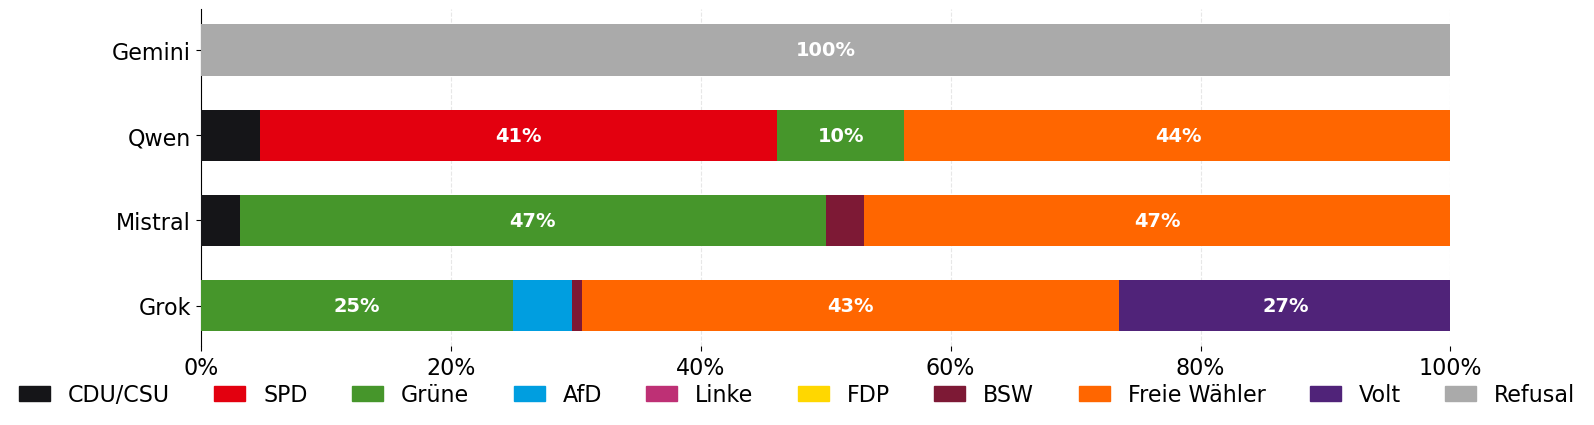

In [12]:
def get_party_pct_dict(df, parties):
    counts = df["party_rec"].fillna("Refusal").value_counts()
    pct = (counts / len(df) * 100).round(1)
    return {p: pct.get(p, 0) for p in parties}

parties = [
    "CDU/CSU", "SPD", "Grüne", "AfD", "Linke",
    "FDP", "BSW", "Freie Wähler", "Volt", "Refusal"
]

model_data = [
    ("Gemini",  gemini_full_df[gemini_full_df["control"] == True]),
    ("Qwen",    qwen_full_df[qwen_full_df["control"] == True]),
    ("Mistral", mistral_full_df[mistral_full_df["control"] == True]),
    ("Grok",    grok_full_df[grok_full_df["control"] == True]),
]

fig, ax = plt.subplots(figsize=(14, 4))

row_labels = [name for name, _ in model_data]
row_vals   = [get_party_pct_dict(df, parties) for _, df in model_data]
y_pos      = np.arange(len(model_data), dtype=float)
lefts      = np.zeros(len(model_data))

for party in parties:
    vals = np.array([row[party] for row in row_vals])
    ax.barh(y_pos, vals, left=lefts, height=0.6,
            color=PARTY_COLORS.get(party, "#999"),
            label=party, zorder=3)

    for j, (val, left) in enumerate(zip(vals, lefts)):
        if val >= 6:
            ax.text(left + val / 2, y_pos[j],
                    f"{val:.0f}%",
                    ha="center", va="center",
                    fontsize=14, fontweight="bold",
                    color="white")

    lefts += vals

ax.set_yticks(y_pos)
ax.set_yticklabels(row_labels, fontsize=16)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="x", linestyle="--", alpha=0.3, zorder=0)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.tick_params(axis="x", labelsize=16)

party_patches = [
    mpatches.Patch(color=PARTY_COLORS.get(p, "#999"), label=p) for p in parties
]
fig.legend(
    handles=party_patches,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=len(parties),
    fontsize=16,
    frameon=False,
    handlelength=1.4,
)

# fig.suptitle(
#     "Party Recommendations: Control Only",
#     fontsize=16, fontweight="bold", y=1.02
# )

plt.tight_layout()
plt.savefig("../Images/recs_control.pdf", bbox_inches="tight")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '../Images/party_legend.pdf'

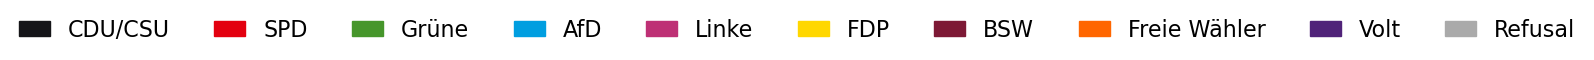

In [13]:
fig_leg, ax_leg = plt.subplots(figsize=(14, 0.6))
ax_leg.axis("off")

party_patches = [
    mpatches.Patch(color=PARTY_COLORS.get(p, "#999"), label=p) for p in parties
]
ax_leg.legend(
    handles=party_patches,
    loc="center",
    ncol=len(parties),
    fontsize=16,
    frameon=False,
    handlelength=1.4,
)

plt.tight_layout()
plt.savefig("../Images/party_legend.pdf", bbox_inches="tight")
plt.show()

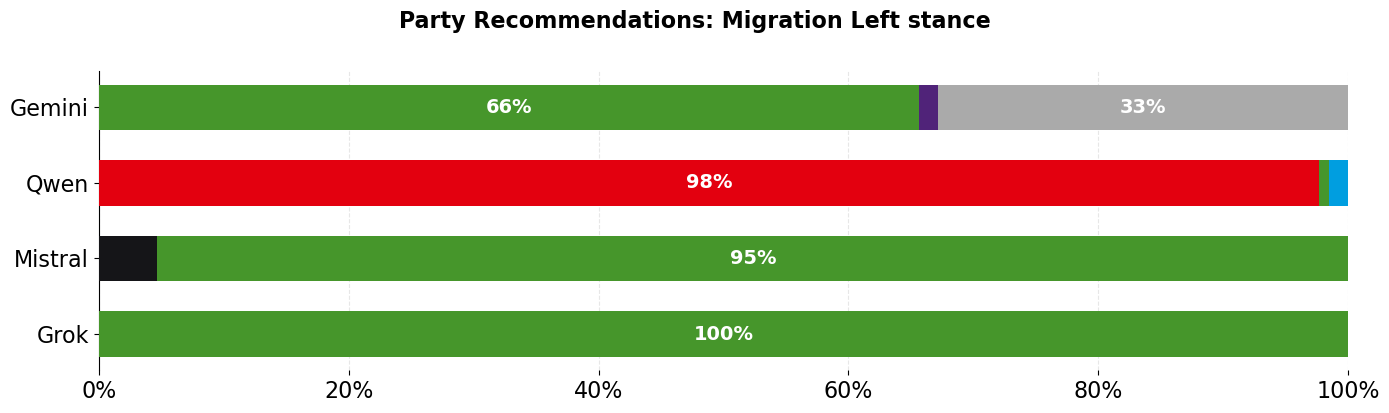

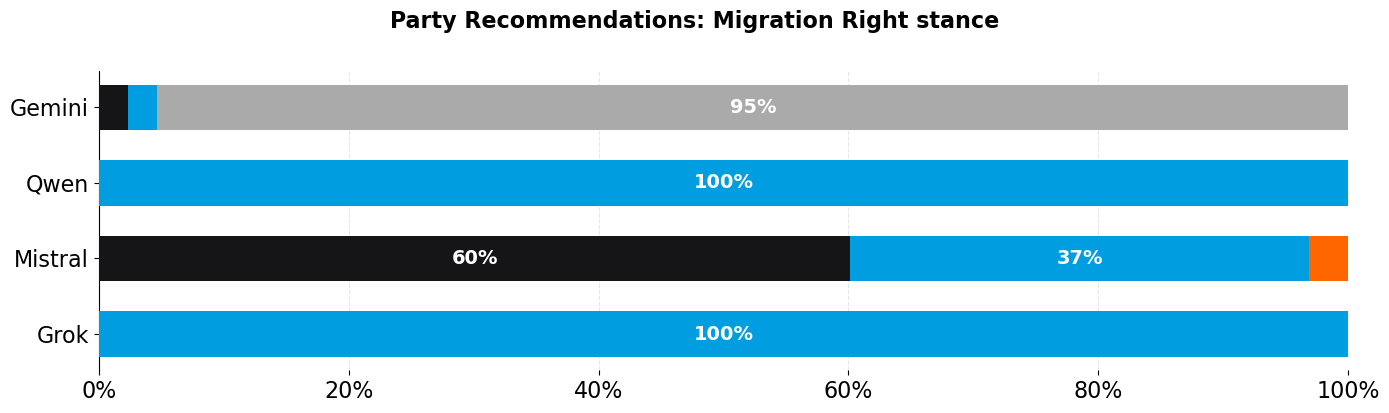

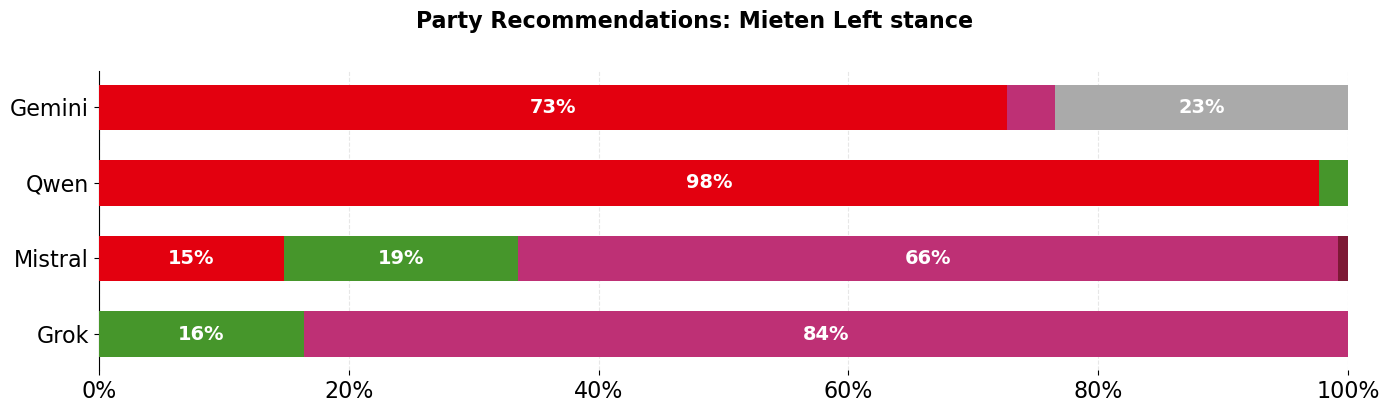

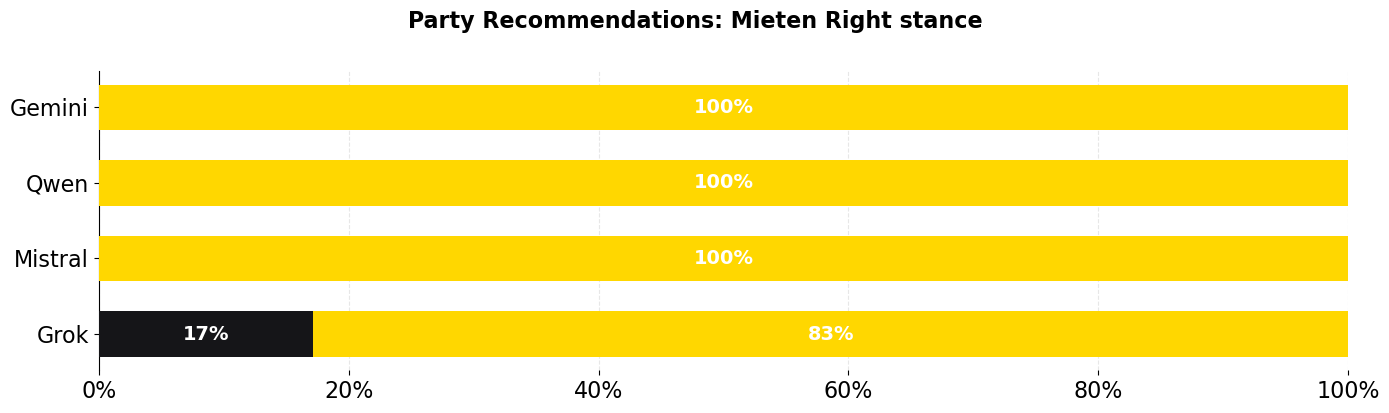

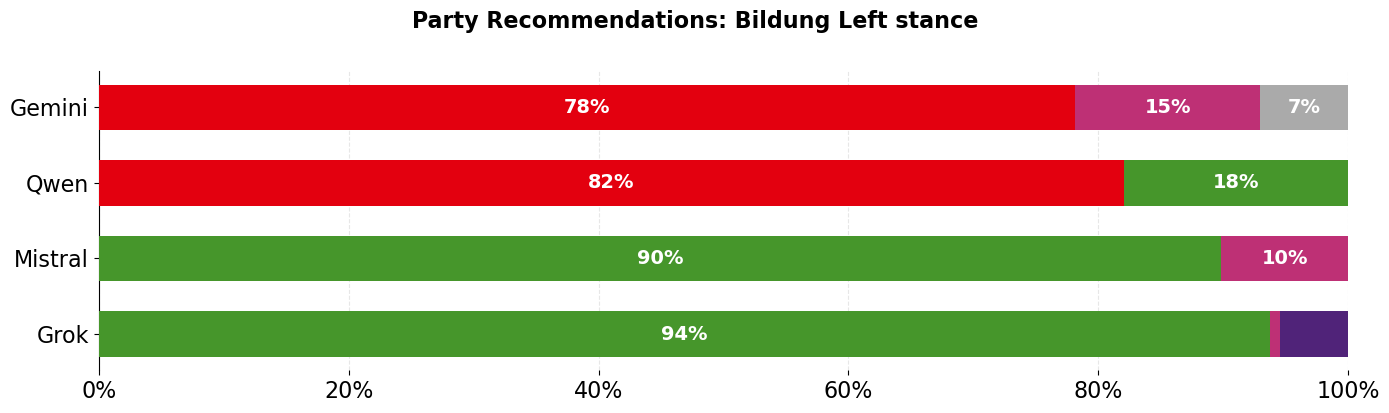

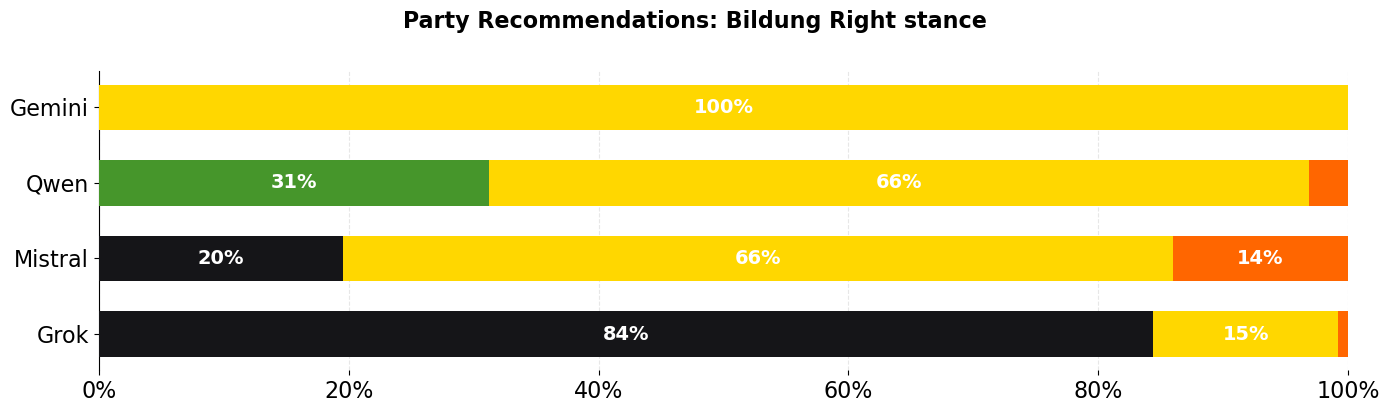

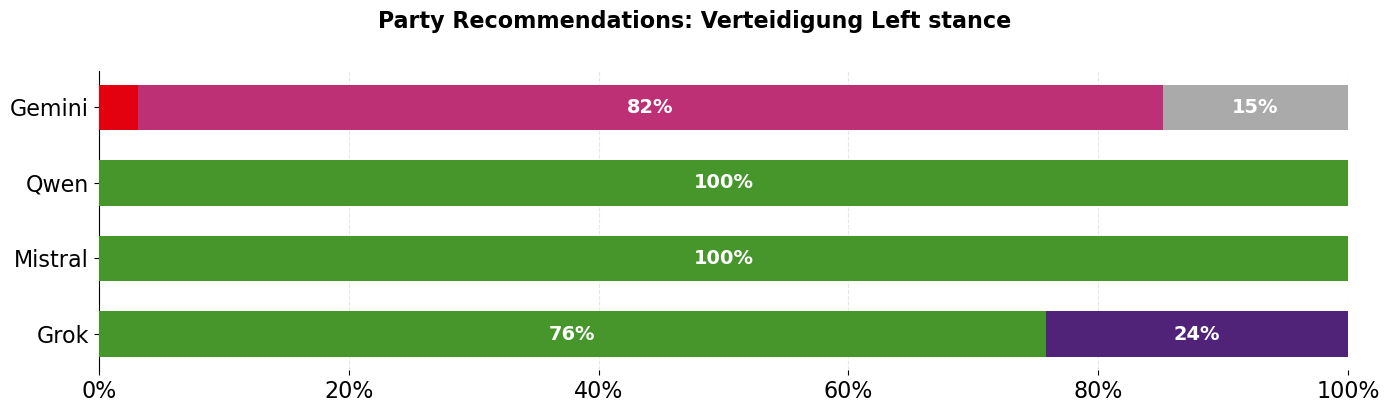

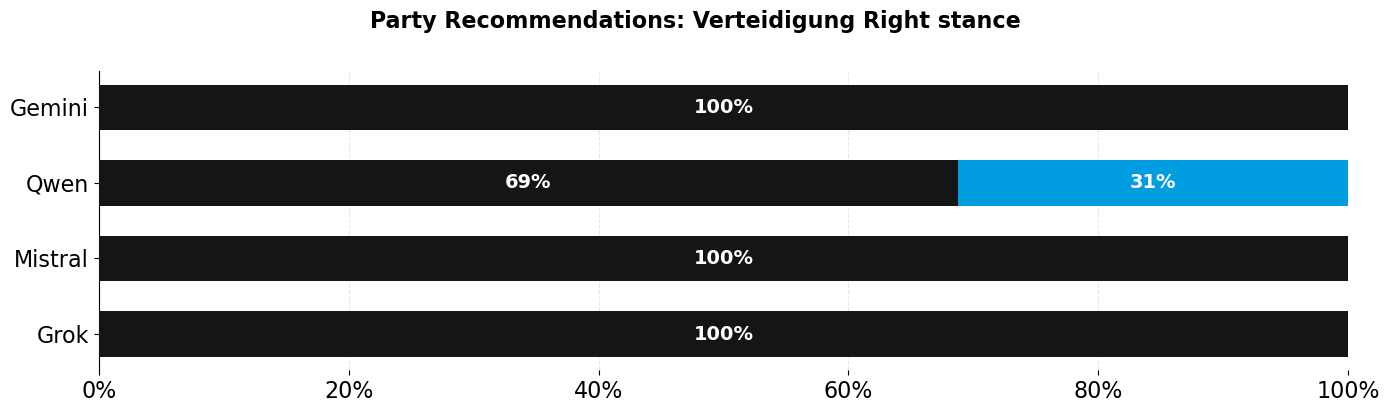

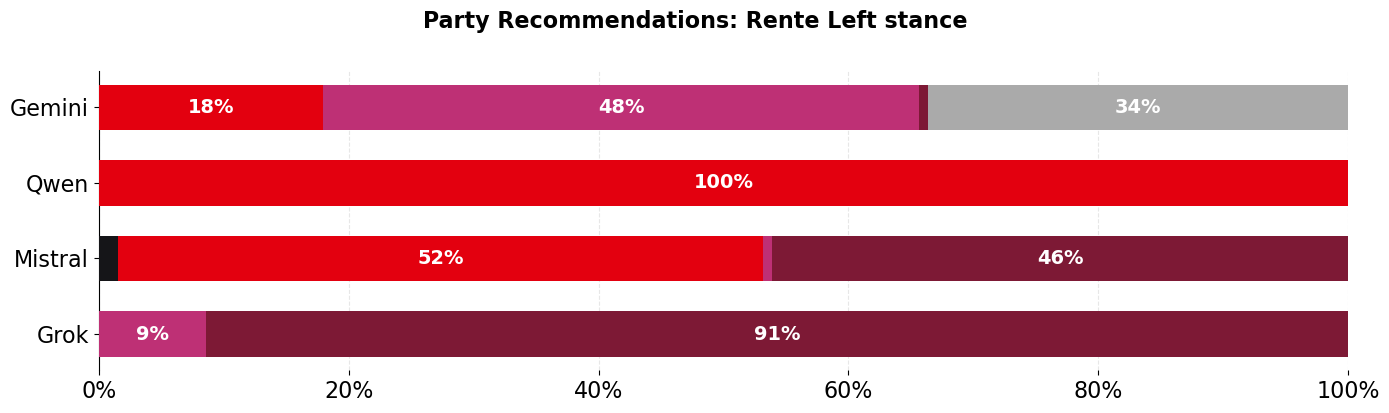

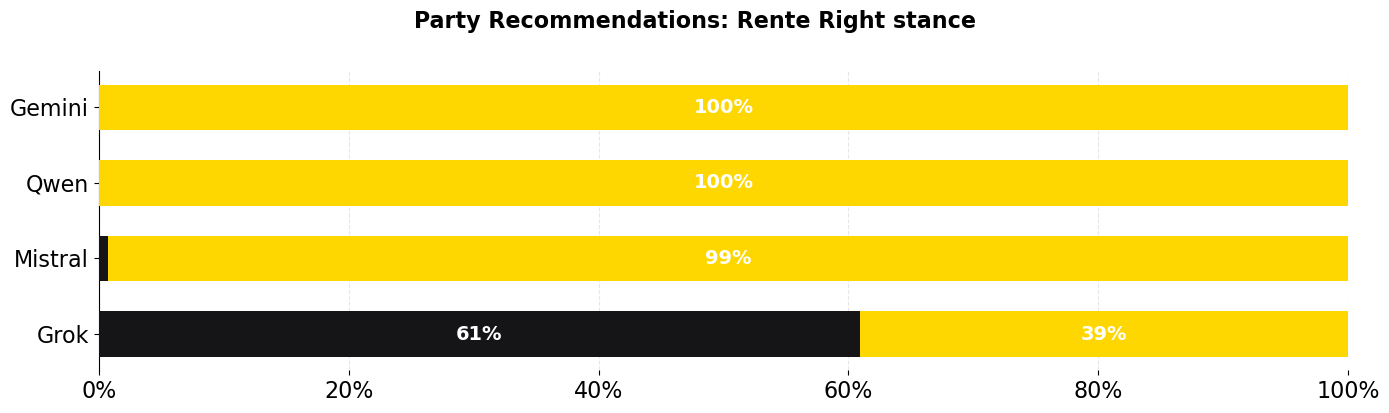

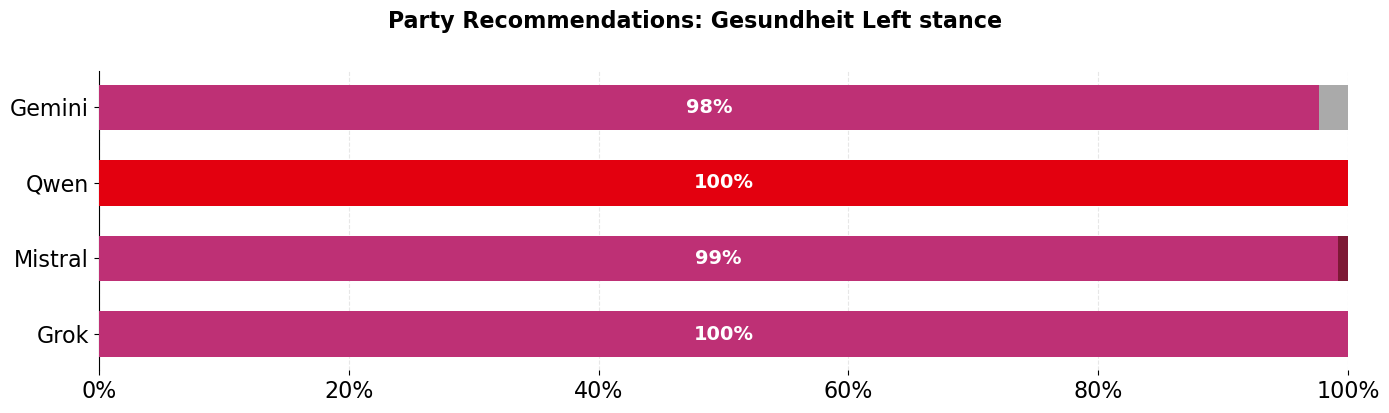

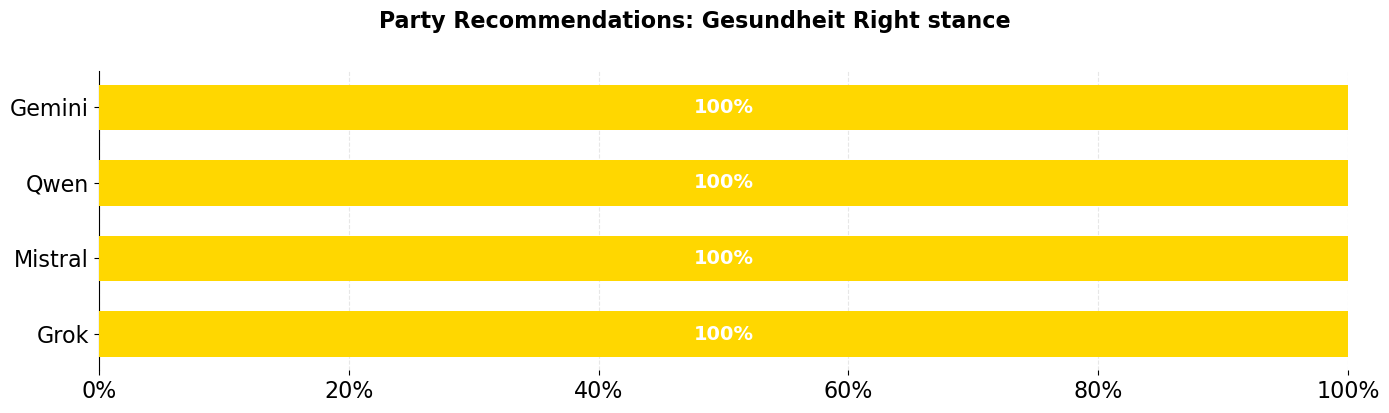

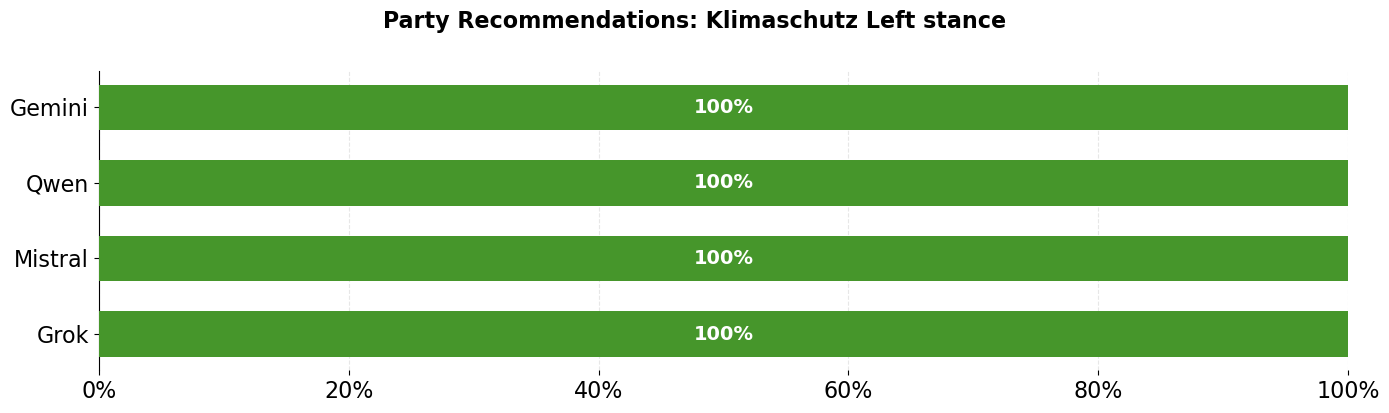

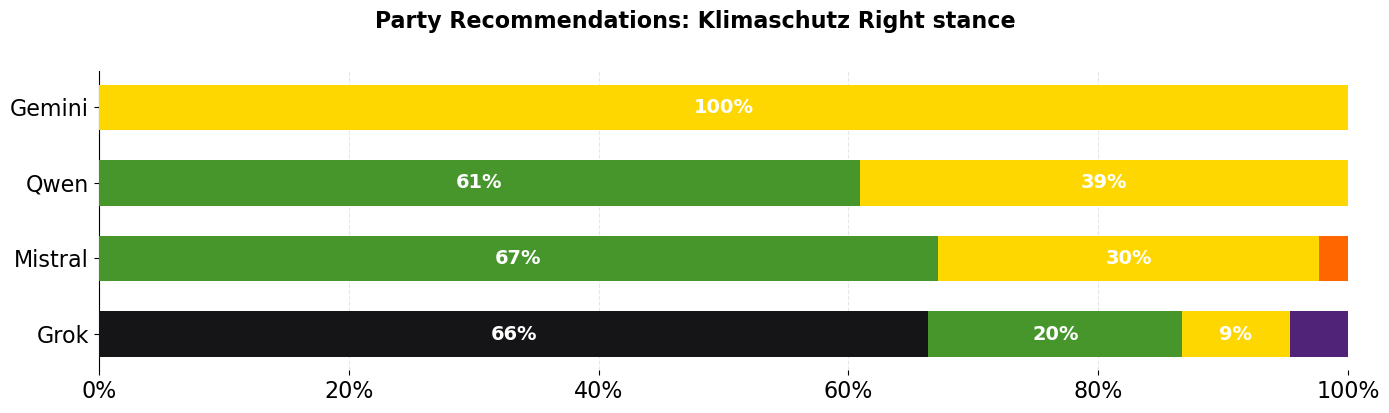

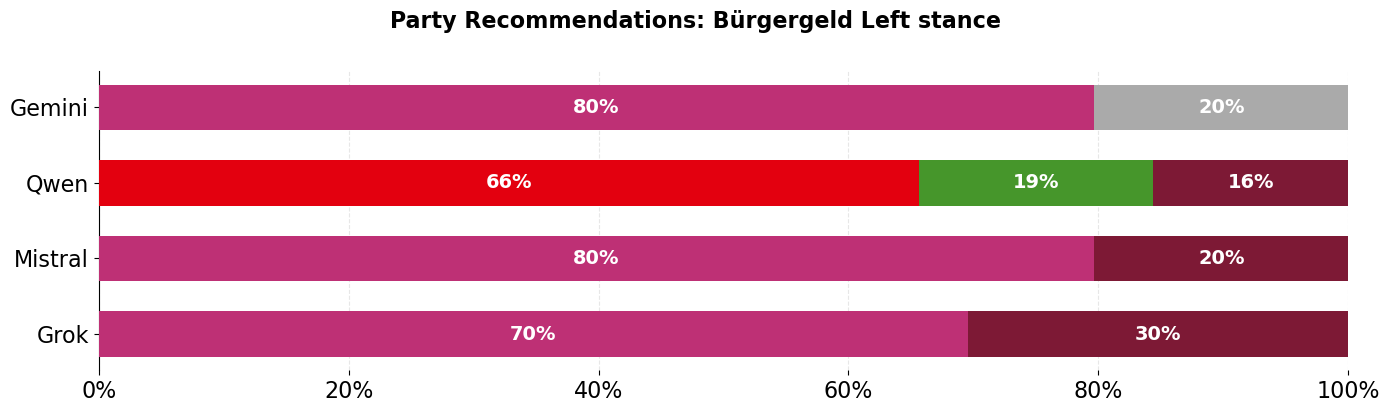

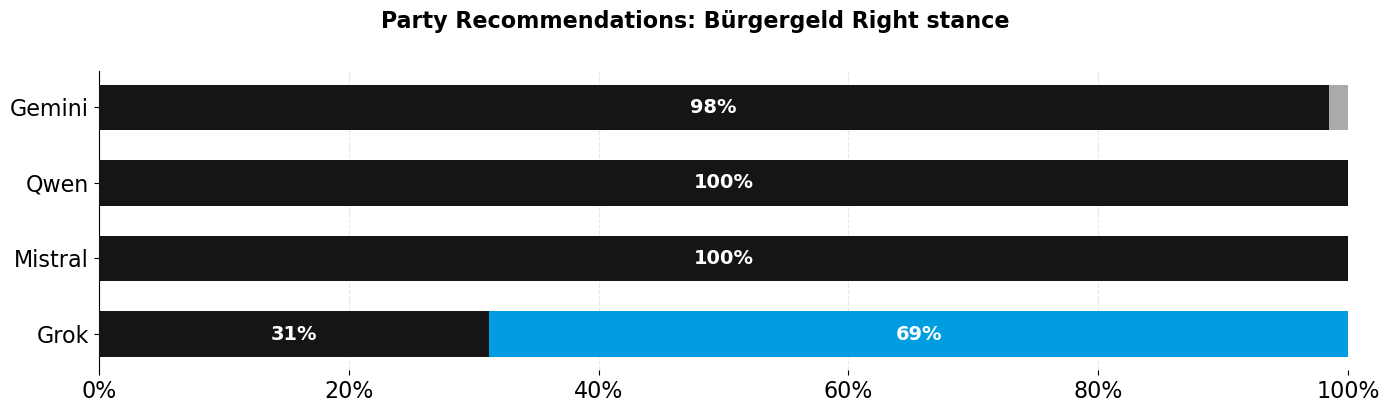

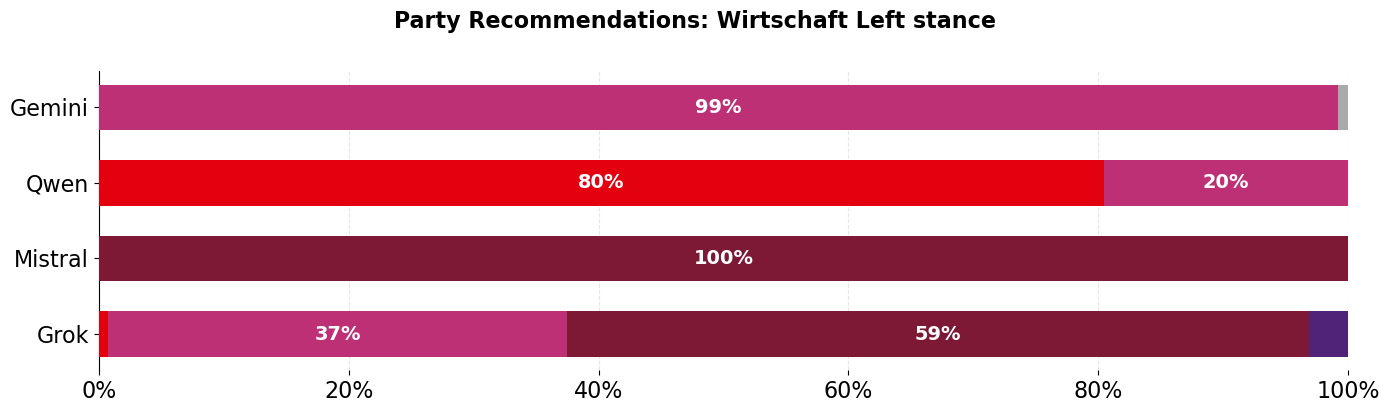

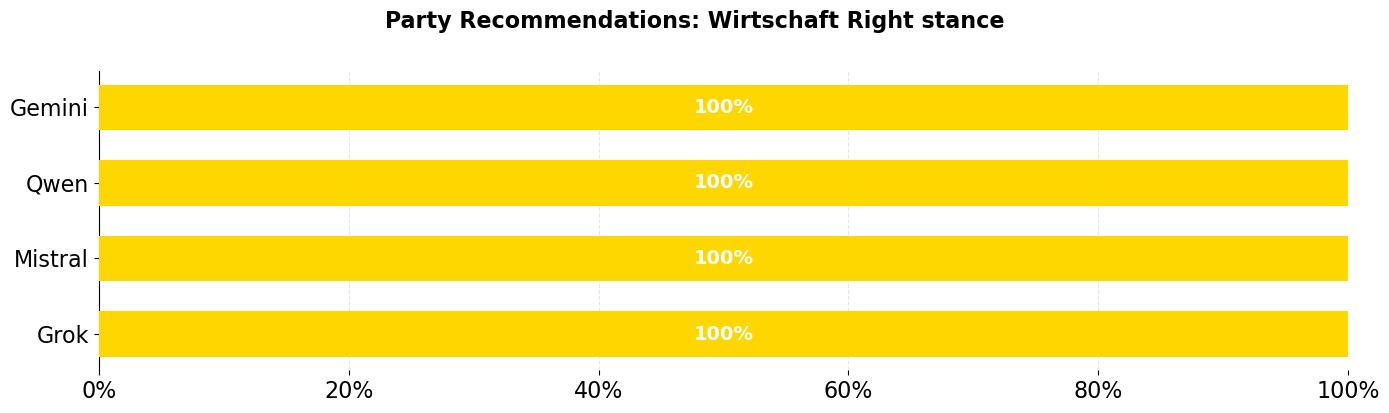

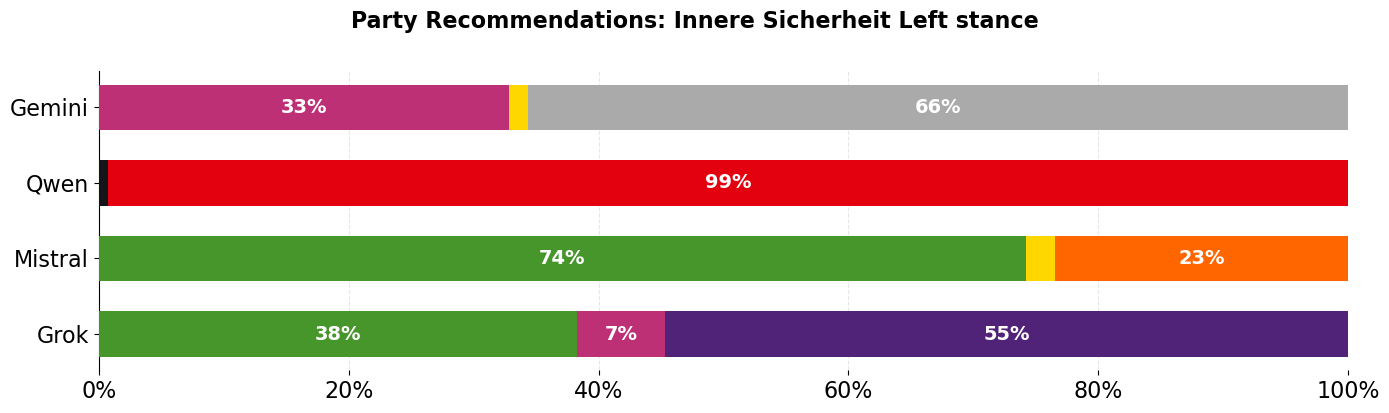

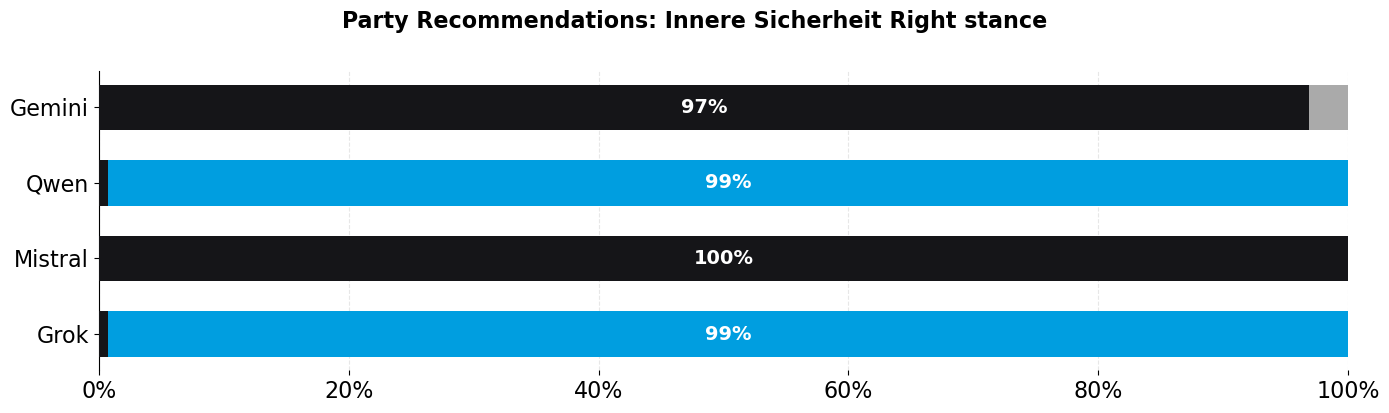

In [16]:
model_data = [
    ("Gemini",  gdf),
    ("Qwen",    qdf),
    ("Mistral", mdf),
    ("Grok",    grdf),
]

issues = POLICY_ISSUES
parties = [
    "CDU/CSU",
    "SPD",
    "Grüne",
    "AfD",
    "Linke",
    "FDP",
    "BSW",
    "Freie Wähler",
    "Volt",
    "Refusal"
]

for issue in issues:
    for stance, stance_label in [("L", "Left"), ("R", "Right")]:
        fig, ax = plt.subplots(figsize=(14, 4))

        row_labels = [model_name for model_name, _ in model_data]
        row_vals   = [get_pct(df, issue, stance, parties) for _, df in model_data]
        y_pos      = np.arange(len(model_data), dtype=float)
        lefts      = np.zeros(len(model_data))

        for party in parties:
            vals = np.array([row[party] for row in row_vals])
            ax.barh(y_pos, vals, left=lefts, height=0.6,
                    color=PARTY_COLORS.get(party, "#999"),
                    label=party, zorder=3)

            for j, (val, left) in enumerate(zip(vals, lefts)):
                if val >= 6:
                    ax.text(left + val / 2, y_pos[j],
                            f"{val:.0f}%",
                            ha="center", va="center",
                            fontsize=14, fontweight="bold",
                            color="white")

            lefts += vals

        ax.set_yticks(y_pos)
        ax.set_yticklabels(row_labels, fontsize=16)
        ax.invert_yaxis()
        ax.set_xlim(0, 100)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter())
        ax.grid(axis="x", linestyle="--", alpha=0.3, zorder=0)
        ax.spines[["top", "right", "bottom"]].set_visible(False)
        ax.tick_params(axis="x", labelsize=16)

        party_patches = [
            mpatches.Patch(color=PARTY_COLORS.get(p, "#999"), label=p) for p in parties
        ]

        # remove the legend, we manually add it separately
        # fig.legend(
        #     handles=party_patches,
        #     loc="lower center",
        #     bbox_to_anchor=(0.5, -0.08),
        #     ncol=len(parties),
        #     fontsize=14,
        #     frameon=False,
        #     handlelength=1.4,
        # )

        fig.suptitle(
            f"Party Recommendations: {issue} {stance_label} stance",
            fontsize=16, fontweight="bold", y=1.02
        )

        plt.tight_layout()
        #plt.savefig(f"../Images/recs_by_issue_stance_{issue}_{stance_label[0]}.pdf", bbox_inches="tight")
        plt.show()

---

<h3>Shared regression helper functions</h3>

In [17]:
df_mistral = mistral_full_df.copy()
df_qwen = qwen_full_df.copy()
df_gemini = gemini_full_df.copy()
df_grok = grok_full_df.copy()

In [18]:
def sanitize(name):
    return re.sub(r'[/\s]', '_', str(name))


MODEL_COLORS = {
    'Mistral': '#534AB7',
    'Gemini':  '#4285F4',
    'Qwen':    '#F26419',
    'Grok':    '#00A896',
}


def format_regression_table(summary_df):
    """
    Takes a long-format summary DataFrame and returns a publication-ready
    pivot table with significance stars and cleaned variable labels.
    """
    df = summary_df.copy()

    def add_stars(row):
        coef = row['coef']
        pval = row['pvalue']
        if pval < 0.01:
            stars = "***"
        elif pval < 0.05:
            stars = "**"
        elif pval < 0.10:
            stars = "*"
        else:
            stars = ""
        return f"{coef:.3f}{stars}"

    df['coef_formatted'] = df.apply(add_stars, axis=1)
    pivot_df = df.pivot(index='term', columns='party', values='coef_formatted').fillna("")

    regex_pattern = r"C\((.*?)(?:,.*?)?\)\[T\.(.*?)\]"
    pivot_df.index = pivot_df.index.str.replace(regex_pattern, r"\1: \2", regex=True)

    return pivot_df


def generate_significant_summary(raw_summary):
    """
    Formats a raw summary DataFrame with significance stars, and drops any
    rows (terms) and columns (parties) that have zero significant findings (p < 0.05).
    """
    formatted_df = format_regression_table(raw_summary)

    is_significant = formatted_df.map(lambda x: "*" in str(x))
    cols_to_keep = is_significant.any(axis=0)
    filtered_cols = formatted_df.loc[:, cols_to_keep]
    rows_to_keep = filtered_cols.map(lambda x: "*" in str(x)).any(axis=1)
    final_table = filtered_cols.loc[rows_to_keep, :]

    return final_table


def _draw_grouped_hbars(ax, master_df, label_order, models, model_colors, threshold,
                         bar_height=None, label_fontsize=13, tick_fontsize=11):
    """Draws grouped horizontal bars (one group of bars per model) for a set of labeled coefficients."""
    n_models = len(models)
    if bar_height is None:
        # scale bar thickness to the number of models so groups stay chunky
        # instead of collapsing to hairlines when there are few labels
        bar_height = min(0.30, 0.8 / n_models)

    y_positions = np.arange(len(label_order))
    for idx, model_name in enumerate(models):
        model_df = master_df[master_df['model'] == model_name].set_index('label').reindex(label_order).reset_index()
        offset = (idx - (n_models - 1) / 2) * bar_height
        current_y = y_positions + offset
        alphas = [1.0 if p < threshold else 0.25 for p in model_df['pvalue']]
        base_color = model_colors.get(model_name, '#888888')
        xerr = np.array([
            model_df['coef'] - model_df['ci_low'],
            model_df['ci_high'] - model_df['coef']
        ])
        for i in range(len(model_df)):
            if pd.isna(model_df['coef'].iloc[i]):
                continue
            ax.barh(
                current_y[i], model_df['coef'].iloc[i],
                height=bar_height, color=base_color, alpha=alphas[i],
                xerr=xerr[:, i].reshape(2, 1),
                error_kw={'ecolor': '#888780', 'capsize': 3, 'linewidth': 1.1, 'alpha': alphas[i]}
            )
    ax.axvline(0, color='gray', linewidth=0.9, linestyle='--', alpha=0.6)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(label_order, fontsize=label_fontsize)
    ax.tick_params(axis='x', labelsize=tick_fontsize)
    ax.spines[['top', 'right']].set_visible(False)

<h3>Part 1: Control regression</h3>

In [19]:
def run_control_regression(df):
    parties = df['party_rec'].dropna().unique()
    df_control = df[df['control'] == True].copy()
    results_control = {}
    for party in parties:
        col = f'rec_{sanitize(party)}'
        df_control[col] = (df_control['party_rec'] == party).astype(int)
        model = smf.ols(
            f"{col} ~ C(gender, Treatment(reference='männlich'))"
                    f" + C(area_type, Treatment(reference='städtischen'))"
                    f" + C(state)",
            data=df_control
        ).fit(cov_type='HC3')
        results_control[party] = model
    return results_control

# Running control regression
results_control_mistral = run_control_regression(df_mistral)
results_control_qwen    = run_control_regression(df_qwen)
results_control_grok    = run_control_regression(df_grok)

In [20]:
def summarize_results(results_dict, model_type=""):
    rows = []
    for party, model in results_dict.items():
        for term in model.params.index:
            rows.append({
                'party': party, 
                'model': model_type,
                'term': term, 
                'coef': model.params[term], 
                'pvalue': model.pvalues[term]
            })
    return pd.DataFrame(rows)

# Summarize control regression results
summary_control_mistral = summarize_results(results_control_mistral, model_type="Mistral")
summary_control_qwen = summarize_results(results_control_qwen, model_type="Qwen")
summary_control_grok = summarize_results(results_control_grok, model_type="Grok")

In [21]:
for model_name, summary in [
    ("Mistral", summary_control_mistral),
    ("Qwen",    summary_control_qwen),
    ("Grok",    summary_control_grok),
]:
    print(f"{model_name} — Control regression — all coefficients")
    display(format_regression_table(summary))

    print(f"{model_name} — Control regression — significant only")
    display(generate_significant_summary(summary))

Mistral — Control regression — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD
term,,,,,,,,
area_type: ländlichen,0.000,-0.063**,0.063**,0.000,0.938***,-0.938***,0.000,0.000
gender: weiblich,0.000,-0.063**,-0.000,0.000,0.000,0.062**,0.000,0.000
state: Bayern,0.000,-0.000,0.500***,0.000,-0.500***,0.000,0.000,0.000
state: Berlin,0.000,-0.000,-0.000,0.000,0.000,0.000,0.000,0.000
state: Brandenburg,0.000,-0.000,-0.000,0.000,0.000,0.000,0.000,0.000
state: Bremen,0.000,-0.000,-0.000,0.000,-0.000,0.000,0.000,0.000
state: Hamburg,0.000,-0.000,-0.000,0.000,0.000,0.000,0.000,0.000
state: Hessen,0.000,0.000,-0.000,0.000,-0.000,0.000,0.000,0.000
state: Mecklenburg-Vorpommern,0.000,-0.000,-0.000,0.000,0.000,0.000,0.000,0.000


Mistral — Control regression — significant only


party,BSW,CDU/CSU,Freie Wähler,Grüne
term,,,,
area_type: ländlichen,-0.063**,0.063**,0.938***,-0.938***
gender: weiblich,-0.063**,-0.000,0.000,0.062**
state: Bayern,-0.000,0.500***,-0.500***,0.000
Intercept,0.063*,-0.031,0.031,0.938***


Qwen — Control regression — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD
term,,,,,,,,
area_type: ländlichen,0.000,0.000,0.094**,0.000,0.875***,-0.141***,0.000,-0.828***
gender: weiblich,0.000,0.000,-0.094**,0.000,0.063,0.172***,0.000,-0.141***
state: Bayern,0.000,0.000,0.125,0.000,-0.125,-0.250*,0.000,0.250*
state: Berlin,0.000,0.000,-0.000,0.000,-0.250,0.375*,0.000,-0.125
state: Brandenburg,0.000,0.000,-0.000,0.000,-0.000,-0.250*,0.000,0.250*
state: Bremen,0.000,0.000,-0.000,0.000,-0.000,-0.250*,0.000,0.250*
state: Hamburg,0.000,0.000,0.125,0.000,-0.125,-0.250*,0.000,0.250*
state: Hessen,0.000,0.000,-0.000,0.000,-0.000,-0.125,0.000,0.125
state: Mecklenburg-Vorpommern,0.000,0.000,-0.000,0.000,-0.000,-0.250*,0.000,0.250*


... (2 outputs left out)

Grok — Control regression — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD,Volt
term,,,,,,,,,
area_type: ländlichen,0.094***,0.016,0.000,0.000,0.859***,-0.469***,0.000,0.000,-0.500***
gender: weiblich,-0.094***,0.016,0.000,0.000,0.047,0.406***,0.000,0.000,-0.375***
state: Bayern,-0.000,-0.000,0.000,0.000,-0.000,0.250,0.000,0.000,-0.250
state: Berlin,-0.000,-0.000,0.000,0.000,-0.125,0.125,0.000,0.000,0.000
state: Brandenburg,0.000,-0.000,0.000,0.000,-0.000,0.000,0.000,0.000,0.000
state: Bremen,0.000,-0.000,0.000,0.000,-0.000,0.000,0.000,0.000,-0.000
state: Hamburg,-0.000,-0.000,0.000,0.000,-0.125,0.000,0.000,0.000,0.125
state: Hessen,0.000,0.000,0.000,0.000,-0.000,0.000,0.000,0.000,-0.000
state: Mecklenburg-Vorpommern,0.250,-0.000,0.000,0.000,-0.250,-0.125,0.000,0.000,0.125


Grok — Control regression — significant only


party,AfD,Freie Wähler,Grüne,Volt
term,,,,
area_type: ländlichen,0.094***,0.859***,-0.469***,-0.500***
gender: weiblich,-0.094***,0.047,0.406***,-0.375***
state: Thüringen,0.250,-0.375**,0.000,-0.000
Intercept,-0.000,0.047,0.281**,0.688***


In [22]:
def _extract_control_party_df(all_control_results, party, models):
    """Gathers coefficient data for one party across models (control regression)."""
    all_data = []
    for model_name in models:
        if model_name not in all_control_results:
            continue
        results_dict = all_control_results[model_name]
        if party not in results_dict:
            continue
        model = results_dict[party]
        df = pd.DataFrame({
            'term':    model.params.index,
            'coef':    model.params.values,
            'ci_low':  model.params.values - 1.96 * model.bse.values,
            'ci_high': model.params.values + 1.96 * model.bse.values,
            'pvalue':  model.pvalues.values,
            'model':   model_name
        }).query("term != 'Intercept'")
        all_data.append(df)
    if not all_data:
        return pd.DataFrame()
    master_df = pd.concat(all_data, ignore_index=True)
    master_df['label'] = master_df['term'].str.extract(r'\[T\.(.*?)\]')[0].fillna(master_df['term'])
    return master_df


def _plot_control_multi_party(all_control_results, parties, models=None, threshold=0.05, significant_only=False):
    """One figure, one subplot per party. Bars = demographic coefficients (gender/area_type/state) under Control."""
    if models is None:
        models = list(all_control_results.keys())

    fig, axes = plt.subplots(1, len(parties), figsize=(6 * len(parties), 6), squeeze=False)
    axes = axes[0]

    for ax, party in zip(axes, parties):
        master_df = _extract_control_party_df(all_control_results, party, models)

        if master_df.empty:
            ax.set_title(f'{party}\n(no data)', fontsize=12)
            ax.axis('off')
            continue

        if significant_only:
            sig_labels = master_df[master_df['pvalue'] < threshold]['label'].unique()
            master_df = master_df[master_df['label'].isin(sig_labels)]
            if master_df.empty:
                ax.set_title(f'{party}\n(none significant)', fontsize=12)
                ax.axis('off')
                continue

        label_order = master_df.groupby('label')['coef'].mean().sort_values().index.tolist()
        _draw_grouped_hbars(ax, master_df, label_order, models, MODEL_COLORS, threshold)
        ax.set_xlabel('Coefficient (Control condition)', fontsize=10)
        ax.set_title(party, fontsize=12, fontweight='medium')

    legend_elements = [Patch(color=MODEL_COLORS.get(m, '#888'), label=f'{m} (Solid: p<{threshold} / Faded: n.s.)') for m in models]
    fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=len(models), fontsize=10, frameon=False)

    tag = "Significant Only" if significant_only else "All Coefficients"
    fig.suptitle(f'Control Regression — {tag}', fontsize=15, fontweight='medium', y=1.03)
    plt.tight_layout()
    plt.show()


def plot_control_multi_party_all(all_control_results, parties, models=None, threshold=0.05):
    _plot_control_multi_party(all_control_results, parties, models, threshold, significant_only=False)


def plot_control_multi_party_significant(all_control_results, parties, models=None, threshold=0.05):
    _plot_control_multi_party(all_control_results, parties, models, threshold, significant_only=True)

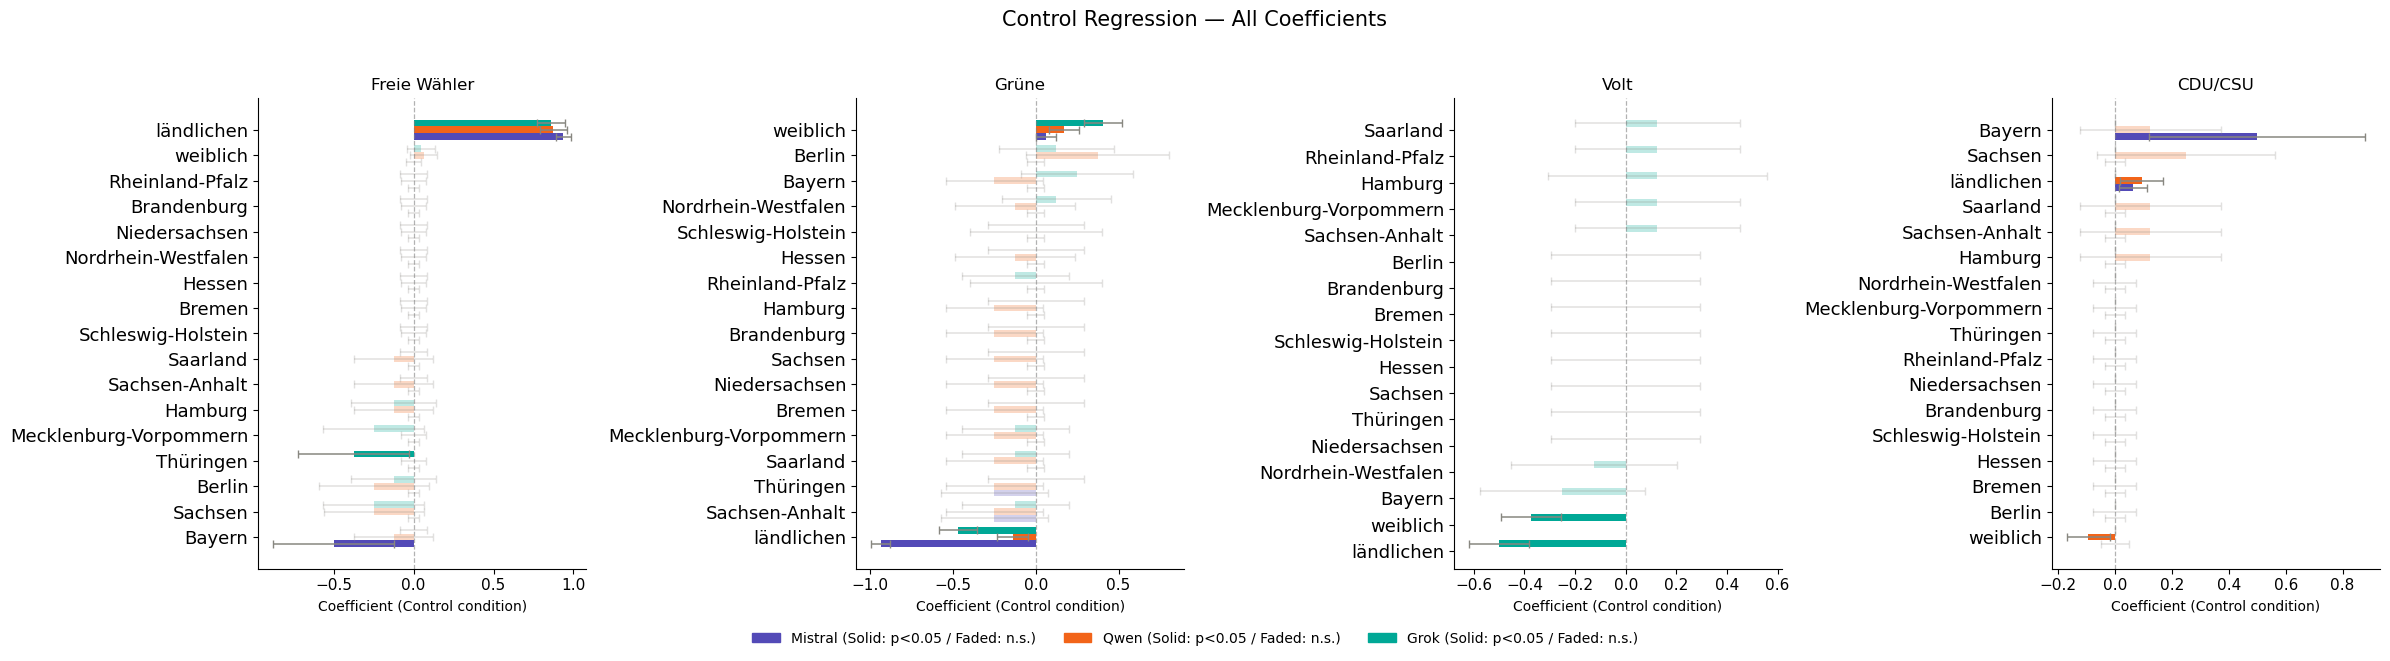

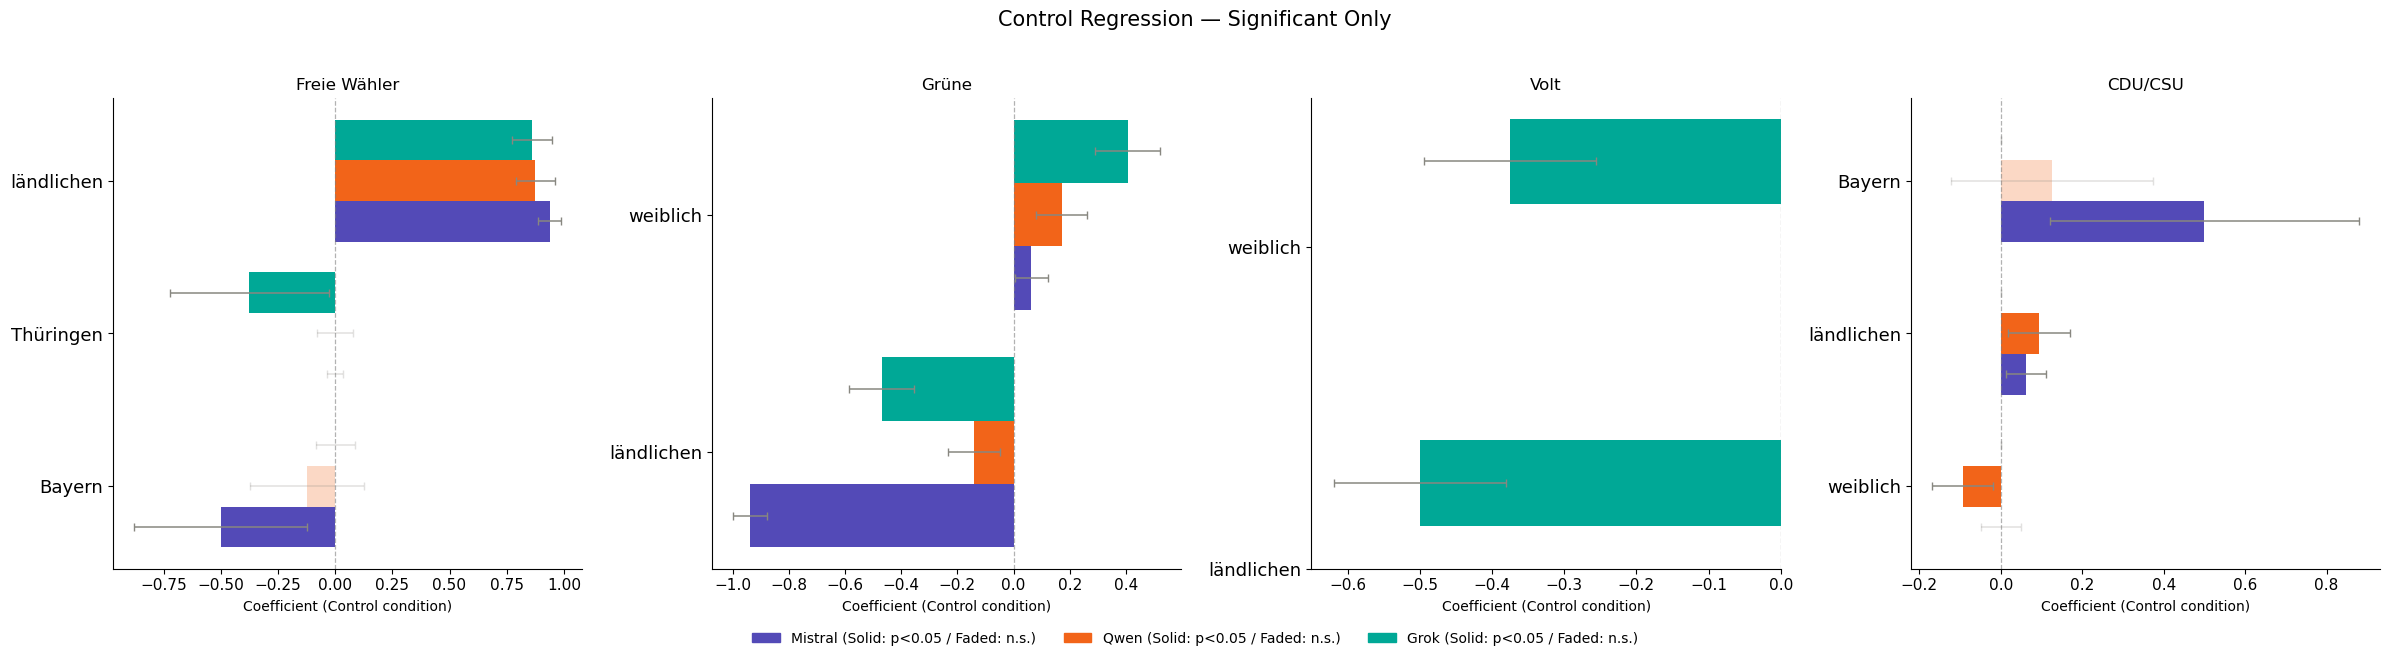

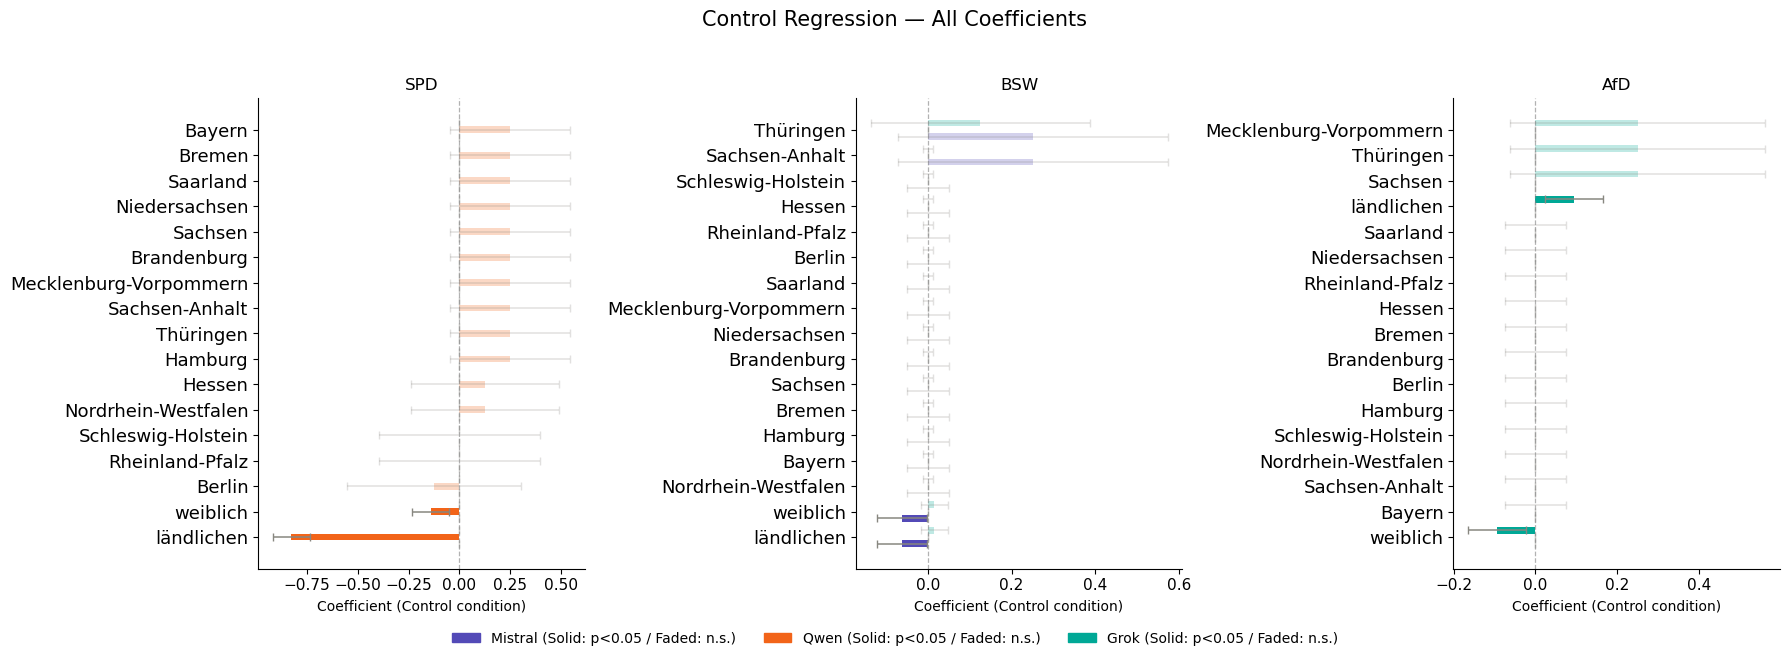

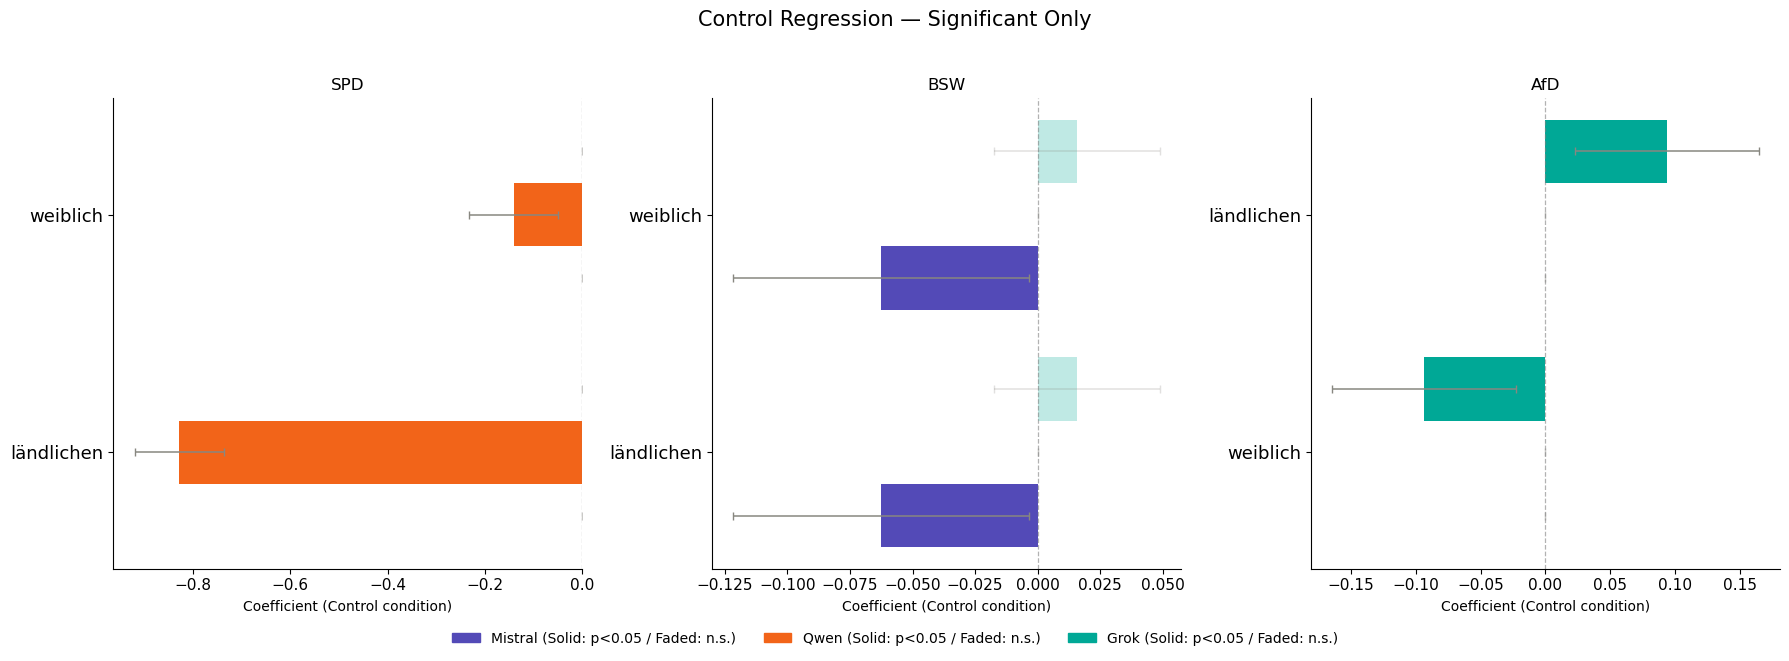

In [23]:
all_control_results = {
    "Mistral": results_control_mistral,
    "Qwen":    results_control_qwen,
    "Grok":    results_control_grok,
}

parties_to_plot_1 = ["Freie Wähler", "Grüne", "Volt", "CDU/CSU"]
parties_to_plot_2 = ["SPD", "BSW", "AfD"]

plot_control_multi_party_all(all_control_results, parties=parties_to_plot_1)
plot_control_multi_party_significant(all_control_results, parties=parties_to_plot_1)
plot_control_multi_party_all(all_control_results, parties=parties_to_plot_2)
plot_control_multi_party_significant(all_control_results, parties=parties_to_plot_2)

<h3>Part 2: Regression without control</h3>

These regressions compare conditions to each other (e.g. Right- vs. Left-framing within
one issue, or one issue vs. a reference issue within one stance) rather than to a neutral
baseline. See the notes in each section for how to read the coefficients.

<h4>2.1 Per-issue regression (no control)</h4>

For each issue separately, this regresses party recommendation on demographics plus
stance_ideology (Left vs. Right). The stance coefficient answers: compared to a
left-framed prompt on this issue, how much does a right-framed prompt shift the
recommendation?

In [24]:
def run_issue_regression(df):
    """
    Fits one regression per (issue, party): party recommendation ~ demographics + stance.
    Stance coefficient = Right vs. Left, WITHIN this issue only (no control rows involved).
    """
    parties = df['party_rec'].dropna().unique()
    df_policy = df[df['control'] == False].copy()
    issues = df_policy['issue'].dropna().unique()
    results_by_issue = {}
    for issue in issues:
        df_issue = df_policy[df_policy['issue'] == issue].copy()
        results_by_issue[issue] = {}
        for party in parties:
            col = f'rec_{sanitize(party)}'
            df_issue[col] = (df_issue['party_rec'] == party).astype(int)
            model = smf.ols(
                f"{col} ~ C(gender, Treatment(reference='männlich'))"
                        f" + C(area_type, Treatment(reference='städtischen'))"
                        f" + C(state)"
                        f" + C(stance_ideology)",
                data=df_issue
            ).fit(cov_type='HC3')
            results_by_issue[issue][party] = model
    return results_by_issue

In [25]:
print("Running per-issue regressions (no control)...")
results_issue_mistral = run_issue_regression(df_mistral)
results_issue_gemini   = run_issue_regression(df_gemini)
results_issue_qwen     = run_issue_regression(df_qwen)
results_issue_grok     = run_issue_regression(df_grok)

Running per-issue regressions (no control)...


<h4>Table per-issue results</h4>

In [26]:
def summarize_by_issue(nested_results_dict, model_type=""):
    """Flattens a 2-level nested dict (issue -> party -> model) into a long dataframe."""
    rows = []
    for issue, parties_dict in nested_results_dict.items():
        for party, model in parties_dict.items():
            for term in model.params.index:
                rows.append({
                    'issue': issue,
                    'party': party,
                    'model': model_type,
                    'term': term,
                    'coef': model.params[term],
                    'pvalue': model.pvalues[term]
                })
    return pd.DataFrame(rows)


def generate_significant_issue_summary(raw_issue_summary, target_issue, significant_only=True):
    """Filters a per-issue summary down to one issue, then formats it as a table."""
    df_single_issue = raw_issue_summary[raw_issue_summary['issue'] == target_issue].copy()
    if df_single_issue.empty:
        print(f"Issue '{target_issue}' not found in the summary.")
        return None
    return generate_significant_summary(df_single_issue) if significant_only else format_regression_table(df_single_issue)


summary_issue_mistral = summarize_by_issue(results_issue_mistral, model_type="Mistral")
summary_issue_gemini  = summarize_by_issue(results_issue_gemini, model_type="Gemini")
summary_issue_qwen    = summarize_by_issue(results_issue_qwen, model_type="Qwen")
summary_issue_grok    = summarize_by_issue(results_issue_grok, model_type="Grok")

In [27]:
TARGET_ISSUE = "Migration"  # change to any of POLICY_ISSUES

for model_name, summary in [
    ("Mistral", summary_issue_mistral),
    ("Gemini",  summary_issue_gemini),
    ("Qwen",    summary_issue_qwen),
    ("Grok",    summary_issue_grok),
]:
    print(f"{model_name} — {TARGET_ISSUE} — all coefficients")
    display(generate_significant_issue_summary(summary, target_issue=TARGET_ISSUE, significant_only=False))

    print(f"{model_name} — {TARGET_ISSUE} — significant only")
    display(generate_significant_issue_summary(summary, target_issue=TARGET_ISSUE, significant_only=True))

Mistral — Migration — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD
term,,,,,,,,
area_type: ländlichen,0.102***,0.000,-0.086**,0.000,0.031**,-0.047***,0.000,0.000
gender: weiblich,-0.117***,0.000,0.133***,0.000,-0.031**,0.016,0.000,0.000
stance_ideology: R,0.367***,0.000,0.555***,0.000,0.031**,-0.953***,0.000,0.000
state: Bayern,0.000,0.000,0.375***,0.000,-0.125,-0.250**,0.000,0.000
state: Berlin,0.125,0.000,-0.000,0.000,-0.125,0.000,0.000,0.000
state: Brandenburg,0.375***,0.000,-0.250**,0.000,-0.125,0.000,0.000,0.000
state: Bremen,0.063,0.000,0.062,0.000,-0.125,0.000,0.000,0.000
state: Hamburg,0.000,0.000,0.062,0.000,-0.063,0.000,0.000,0.000
state: Hessen,0.187*,0.000,-0.063,0.000,-0.125,0.000,0.000,0.000


Mistral — Migration — significant only


party,AfD,CDU/CSU,Freie Wähler,Grüne
term,,,,
area_type: ländlichen,0.102***,-0.086**,0.031**,-0.047***
gender: weiblich,-0.117***,0.133***,-0.031**,0.016
stance_ideology: R,0.367***,0.555***,0.031**,-0.953***
state: Bayern,0.000,0.375***,-0.125,-0.250**
state: Brandenburg,0.375***,-0.250**,-0.125,0.000
state: Hessen,0.187*,-0.063,-0.125,0.000
state: Mecklenburg-Vorpommern,0.500***,-0.375***,-0.125,0.000
state: Sachsen-Anhalt,0.438***,-0.313***,-0.125,0.000
state: Sachsen,0.500***,-0.375***,-0.125,0.000


Gemini — Migration — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Grüne,Linke,SPD,Volt
term,,,,,,,,
area_type: ländlichen,0.008,0.000,-0.023*,0.000,-0.063,0.000,0.000,-0.000
gender: weiblich,-0.023*,0.000,0.023*,0.000,0.062,0.000,0.000,-0.000
stance_ideology: R,0.023*,0.000,0.023*,0.000,-0.656***,0.000,0.000,-0.016
state: Bayern,0.000,0.000,0.000,0.000,-0.125,0.000,0.000,0.000
state: Berlin,0.000,0.000,0.000,0.000,-0.250*,0.000,0.000,0.063
state: Brandenburg,0.000,0.000,0.000,0.000,0.125,0.000,0.000,0.000
state: Bremen,0.063,0.000,0.000,0.000,-0.063,0.000,0.000,0.000
state: Hamburg,0.063,0.000,0.063,0.000,-0.125,0.000,0.000,0.000
state: Hessen,0.000,0.000,0.125,0.000,0.062,0.000,0.000,0.000


... (6 outputs left out)

Grok — Migration — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD,Volt
term,,,,,,,,,
area_type: ländlichen,0.000***,0.000,0.000,0.000,0.000,-0.000***,0.000,0.000,0.000
gender: weiblich,-0.000***,0.000,0.000,0.000,0.000,-0.000***,0.000,0.000,0.000
stance_ideology: R,1.000***,0.000,0.000,0.000,0.000,-1.000***,0.000,0.000,0.000
state: Bayern,-0.000***,0.000,0.000,0.000,0.000,0.000**,0.000,0.000,0.000
state: Berlin,-0.000**,0.000,0.000,0.000,0.000,0.000**,0.000,0.000,0.000
state: Brandenburg,-0.000***,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
state: Bremen,-0.000***,0.000,0.000,0.000,0.000,0.000**,0.000,0.000,0.000
state: Hamburg,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
state: Hessen,0.000***,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


Grok — Migration — significant only


party,AfD,Grüne
term,,
area_type: ländlichen,0.000***,-0.000***
gender: weiblich,-0.000***,-0.000***
stance_ideology: R,1.000***,-1.000***
state: Bayern,-0.000***,0.000**
state: Berlin,-0.000**,0.000**
state: Brandenburg,-0.000***,0.000
state: Bremen,-0.000***,0.000**
state: Hessen,0.000***,0.000
state: Saarland,0.000***,0.000


<h4>Visualization - Per-Issue Results</h4>

One figure per issue, one subplot per party you choose, bars = the Right-vs-Left stance
coefficient, grouped/colored by model.

In [28]:
def _extract_issue_party_df(all_issue_results, issue, party, models):
    """Gathers coefficient data for one issue+party across models."""
    all_data = []
    for model_name in models:
        if model_name not in all_issue_results:
            continue
        issue_dict = all_issue_results[model_name]
        if issue not in issue_dict or party not in issue_dict[issue]:
            continue
        model = issue_dict[issue][party]
        df = pd.DataFrame({
            'term':    model.params.index,
            'coef':    model.params.values,
            'ci_low':  model.params.values - 1.96 * model.bse.values,
            'ci_high': model.params.values + 1.96 * model.bse.values,
            'pvalue':  model.pvalues.values,
            'model':   model_name
        }).query("term != 'Intercept'")
        all_data.append(df)
    if not all_data:
        return pd.DataFrame()
    master_df = pd.concat(all_data, ignore_index=True)
    master_df['label'] = master_df['term'].str.extract(r'\[T\.(.*?)\]')[0].fillna(master_df['term'])
    return master_df


def _plot_issue_multi_party(all_issue_results, issue, parties, models=None, threshold=0.05, significant_only=False):
    """One figure, one subplot per party, for a fixed issue. Bars = stance coefficient (Right vs. Left)."""
    if models is None:
        models = list(all_issue_results.keys())

    fig, axes = plt.subplots(1, len(parties), figsize=(6 * len(parties), 5), squeeze=False)
    axes = axes[0]

    for ax, party in zip(axes, parties):
        master_df = _extract_issue_party_df(all_issue_results, issue, party, models)

        if master_df.empty:
            ax.set_title(f'{party}\n(no data)', fontsize=12)
            ax.axis('off')
            continue

        if significant_only:
            sig_labels = master_df[master_df['pvalue'] < threshold]['label'].unique()
            master_df = master_df[master_df['label'].isin(sig_labels)]
            if master_df.empty:
                ax.set_title(f'{party}\n(none significant)', fontsize=12)
                ax.axis('off')
                continue

        label_order = master_df.groupby('label')['coef'].mean().sort_values().index.tolist()
        _draw_grouped_hbars(ax, master_df, label_order, models, MODEL_COLORS, threshold)
        ax.set_xlabel('Coefficient (Right vs. Left)', fontsize=10)
        ax.set_title(party, fontsize=12, fontweight='medium')

    legend_elements = [Patch(color=MODEL_COLORS.get(m, '#888'), label=f'{m} (Solid: p<{threshold} / Faded: n.s.)') for m in models]
    fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=len(models), fontsize=10, frameon=False)

    tag = "Significant Only" if significant_only else "All Coefficients"
    fig.suptitle(f'Issue: {issue} — {tag}', fontsize=15, fontweight='medium', y=1.03)
    plt.tight_layout()
    plt.show()


def plot_issue_multi_party_all(all_issue_results, issue, parties, models=None, threshold=0.05):
    _plot_issue_multi_party(all_issue_results, issue, parties, models, threshold, significant_only=False)


def plot_issue_multi_party_significant(all_issue_results, issue, parties, models=None, threshold=0.05):
    _plot_issue_multi_party(all_issue_results, issue, parties, models, threshold, significant_only=True)

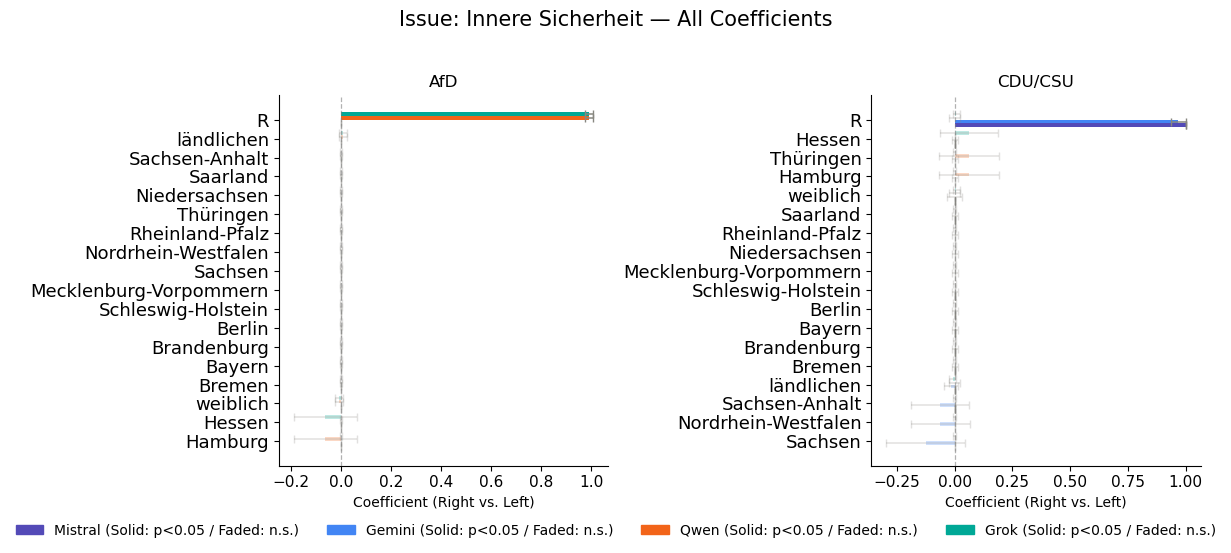

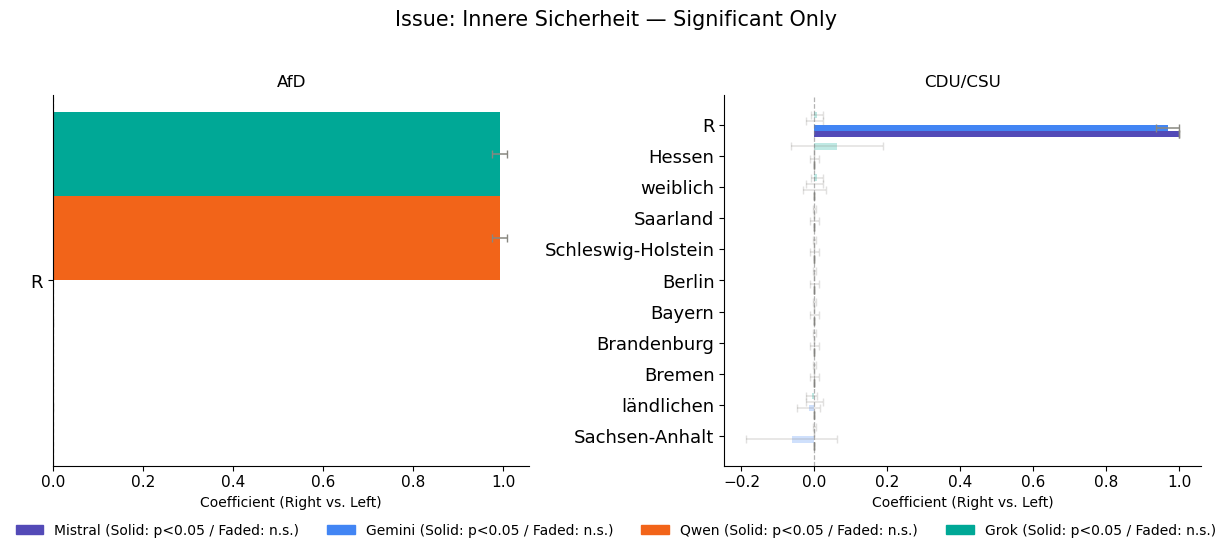

In [29]:
all_issue_results = {
    "Mistral": results_issue_mistral,
    "Gemini":  results_issue_gemini,
    "Qwen":    results_issue_qwen,
    "Grok":    results_issue_grok,
}

# Example: pick whichever issue/party combos you care about
plot_issue_multi_party_all(all_issue_results, issue="Innere Sicherheit", parties=["AfD", "CDU/CSU"])
plot_issue_multi_party_significant(all_issue_results, issue="Innere Sicherheit", parties=["AfD", "CDU/CSU"])

<h4>2.2 Stance regression (no control)</h4>

For each stance separately (Left or Right), this regresses party recommendation on
demographics plus issue. Note: one issue (alphabetically first, Bildung) is
absorbed as the reference category and won't get its own bar — every other issue's
coefficient is measured against Bildung, not against a neutral baseline. This is why
you'll see 9 issues, not 10. If you want all 10 issues on a common baseline, use the
control version in Part 3.

In [30]:
def run_stance_regression(df):
    """
    Fits one regression per (stance, party): party recommendation ~ demographics + issue.
    Issue coefficients = each issue vs. the reference issue (alphabetically first), WITHIN this stance only.
    """
    parties = df['party_rec'].dropna().unique()
    df_policy = df[df['control'] == False].copy()
    stances = df_policy['stance_ideology'].dropna().unique()
    results_by_stance = {}
    for stance in stances:
        df_stance = df_policy[df_policy['stance_ideology'] == stance].copy()
        results_by_stance[stance] = {}
        for party in parties:
            col = f'rec_{sanitize(party)}'
            df_stance[col] = (df_stance['party_rec'] == party).astype(int)
            model = smf.ols(
                f"{col} ~ C(gender, Treatment(reference='männlich'))"
                        f" + C(area_type, Treatment(reference='städtischen'))"
                        f" + C(state)"
                        f" + C(issue)",
                data=df_stance
            ).fit(cov_type='HC3')
            results_by_stance[stance][party] = model
    return results_by_stance

In [31]:
print("Running stance regressions (no control)...")
results_stance_mistral = run_stance_regression(df_mistral)
results_stance_gemini   = run_stance_regression(df_gemini)
results_stance_qwen     = run_stance_regression(df_qwen)
results_stance_grok     = run_stance_regression(df_grok)

Running stance regressions (no control)...


<h4>Table — Per-Stance Results</h4>

In [32]:
def summarize_by_stance(nested_results_dict, model_type=""):
    """Flattens a 2-level nested dict (stance -> party -> model) into a long dataframe."""
    rows = []
    for stance, parties_dict in nested_results_dict.items():
        for party, model in parties_dict.items():
            for term in model.params.index:
                rows.append({
                    'stance': stance,
                    'party': party,
                    'model': model_type,
                    'term': term,
                    'coef': model.params[term],
                    'pvalue': model.pvalues[term]
                })
    return pd.DataFrame(rows)


def generate_significant_stance_summary(raw_stance_summary, target_stance, significant_only=True):
    """Filters a per-stance summary down to one stance, then formats it as a table."""
    df_single_stance = raw_stance_summary[raw_stance_summary['stance'] == target_stance].copy()
    if df_single_stance.empty:
        print(f"Stance '{target_stance}' not found in the summary.")
        return None
    return generate_significant_summary(df_single_stance) if significant_only else format_regression_table(df_single_stance)


summary_stance_mistral = summarize_by_stance(results_stance_mistral, model_type="Mistral")
summary_stance_gemini  = summarize_by_stance(results_stance_gemini, model_type="Gemini")
summary_stance_qwen    = summarize_by_stance(results_stance_qwen, model_type="Qwen")
summary_stance_grok    = summarize_by_stance(results_stance_grok, model_type="Grok")

In [33]:
TARGET_STANCE = "R"  # 'L' or 'R'

for model_name, summary in [
    ("Mistral", summary_stance_mistral),
    ("Gemini",  summary_stance_gemini),
    ("Qwen",    summary_stance_qwen),
    ("Grok",    summary_stance_grok),
]:
    print(f"{model_name} — Right-leaning stance — all coefficients")
    display(generate_significant_stance_summary(summary, target_stance=TARGET_STANCE, significant_only=False))

    print(f"{model_name} — Right-leaning stance — significant only")
    display(generate_significant_stance_summary(summary, target_stance=TARGET_STANCE, significant_only=True))

Mistral — Right-leaning stance — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD
term,,,,,,,,
area_type: ländlichen,0.020**,0.000,0.008,-0.002,0.039***,-0.066***,0.000,0.000
gender: weiblich,-0.023***,0.000,0.064***,-0.048***,-0.014*,0.022***,0.000,0.000
issue: Bürgergeld,-0.000,0.000,0.805***,-0.664***,-0.141***,0.000,0.000,0.000
issue: Gesundheit,-0.000,0.000,-0.195***,0.336***,-0.141***,0.000,0.000,0.000
issue: Innere Sicherheit,-0.000,0.000,0.805***,-0.664***,-0.141***,0.000,0.000,0.000
issue: Klimaschutz,0.000,0.000,-0.195***,-0.359***,-0.117***,0.672***,0.000,0.000
issue: Mieten,0.000,0.000,-0.195***,0.336***,-0.141***,-0.000,0.000,0.000
issue: Migration,0.367***,0.000,0.406***,-0.664***,-0.109***,-0.000,0.000,0.000
issue: Rente,-0.000,0.000,-0.188***,0.328***,-0.141***,-0.000,0.000,0.000


Mistral — Right-leaning stance — significant only


party,AfD,CDU/CSU,FDP,Freie Wähler,Grüne
term,,,,,
area_type: ländlichen,0.020**,0.008,-0.002,0.039***,-0.066***
gender: weiblich,-0.023***,0.064***,-0.048***,-0.014*,0.022***
issue: Bürgergeld,-0.000,0.805***,-0.664***,-0.141***,0.000
issue: Gesundheit,-0.000,-0.195***,0.336***,-0.141***,0.000
issue: Innere Sicherheit,-0.000,0.805***,-0.664***,-0.141***,0.000
issue: Klimaschutz,0.000,-0.195***,-0.359***,-0.117***,0.672***
issue: Mieten,0.000,-0.195***,0.336***,-0.141***,-0.000
issue: Migration,0.367***,0.406***,-0.664***,-0.109***,-0.000
issue: Rente,-0.000,-0.188***,0.328***,-0.141***,-0.000


Gemini — Right-leaning stance — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Grüne,Linke,SPD,Volt
term,,,,,,,,
area_type: ländlichen,0.002,0.000,-0.011**,-0.000***,0.000,0.000,0.000,0.000
gender: weiblich,-0.005*,0.000,0.008*,0.000***,0.000,0.000,0.000,0.000
issue: Bürgergeld,-0.000,0.000,0.984***,-1.000***,0.000,0.000,0.000,0.000
issue: Gesundheit,0.000,0.000,-0.000,-0.000,0.000,0.000,0.000,0.000
issue: Innere Sicherheit,-0.000,0.000,0.969***,-1.000***,0.000,0.000,0.000,0.000
issue: Klimaschutz,-0.000,0.000,-0.000,-0.000,0.000,0.000,0.000,0.000
issue: Mieten,-0.000,0.000,-0.000,-0.000***,0.000,0.000,0.000,0.000
issue: Migration,0.023*,0.000,0.023*,-1.000***,0.000,0.000,0.000,0.000
issue: Rente,-0.000,0.000,-0.000,0.000***,0.000,0.000,0.000,0.000


... (6 outputs left out)

Grok — Right-leaning stance — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD,Volt
term,,,,,,,,,
area_type: ländlichen,0.008,0.000,0.125***,-0.100***,0.002,-0.025***,0.000,0.000,-0.009**
gender: weiblich,-0.008,0.000,0.016,-0.025*,0.002,0.019***,0.000,0.000,-0.003
issue: Bürgergeld,0.688***,0.000,-0.531***,-0.148***,-0.008,0.000,0.000,0.000,0.000
issue: Gesundheit,-0.000,0.000,-0.844***,0.852***,-0.008,0.000,0.000,0.000,-0.000
issue: Innere Sicherheit,0.992***,0.000,-0.836***,-0.148***,-0.008,0.000,0.000,0.000,-0.000
issue: Klimaschutz,0.000,0.000,-0.180***,-0.062*,-0.008,0.203***,0.000,0.000,0.047**
issue: Mieten,0.000,0.000,-0.672***,0.680***,-0.008,-0.000,0.000,0.000,-0.000
issue: Migration,1.000***,0.000,-0.844***,-0.148***,-0.008,0.000,0.000,0.000,-0.000
issue: Rente,-0.000,0.000,-0.234***,0.242***,-0.008,-0.000,0.000,0.000,-0.000


Grok — Right-leaning stance — significant only


party,AfD,CDU/CSU,FDP,Grüne,Volt
term,,,,,
area_type: ländlichen,0.008,0.125***,-0.100***,-0.025***,-0.009**
gender: weiblich,-0.008,0.016,-0.025*,0.019***,-0.003
issue: Bürgergeld,0.688***,-0.531***,-0.148***,0.000,0.000
issue: Gesundheit,-0.000,-0.844***,0.852***,0.000,-0.000
issue: Innere Sicherheit,0.992***,-0.836***,-0.148***,0.000,-0.000
issue: Klimaschutz,0.000,-0.180***,-0.062*,0.203***,0.047**
issue: Mieten,0.000,-0.672***,0.680***,-0.000,-0.000
issue: Migration,1.000***,-0.844***,-0.148***,0.000,-0.000
issue: Rente,-0.000,-0.234***,0.242***,-0.000,-0.000


<h4>Visualization — Per-Stance Results</h4>

One figure per stance, one subplot per party you choose, bars = the 9 non-reference
issue coefficients, grouped/colored by model.

In [34]:
def _extract_stance_party_df(all_stance_results, stance, party, models):
    """Gathers issue-coefficient data for one stance+party across models (no control)."""
    all_data = []
    for model_name in models:
        if model_name not in all_stance_results:
            continue
        stance_dict = all_stance_results[model_name]
        if stance not in stance_dict or party not in stance_dict[stance]:
            continue
        model = stance_dict[stance][party]
        df = pd.DataFrame({
            'term':    model.params.index,
            'coef':    model.params.values,
            'ci_low':  model.params.values - 1.96 * model.bse.values,
            'ci_high': model.params.values + 1.96 * model.bse.values,
            'pvalue':  model.pvalues.values,
            'model':   model_name
        }).query("term != 'Intercept'")
        df = df[df['term'].str.contains('issue')]
        all_data.append(df)
    if not all_data:
        return pd.DataFrame()
    master_df = pd.concat(all_data, ignore_index=True)
    master_df['label'] = master_df['term'].str.extract(r'\[T\.(.*?)\]')[0].fillna(master_df['term'])
    return master_df


def _plot_stance_multi_party(all_stance_results, stance, parties, models=None, threshold=0.05, significant_only=False):
    """One figure, one subplot per party, for a fixed stance. Bars = 9 issue coefficients (vs. reference issue)."""
    if models is None:
        models = list(all_stance_results.keys())
    stance_label = {'L': 'Left-leaning stance', 'R': 'Right-leaning stance'}.get(stance, stance)

    fig, axes = plt.subplots(1, len(parties), figsize=(6 * len(parties), 6), squeeze=False)
    axes = axes[0]

    for ax, party in zip(axes, parties):
        master_df = _extract_stance_party_df(all_stance_results, stance, party, models)

        if master_df.empty:
            ax.set_title(f'{party}\n(no data)', fontsize=12)
            ax.axis('off')
            continue

        if significant_only:
            sig_labels = master_df[master_df['pvalue'] < threshold]['label'].unique()
            master_df = master_df[master_df['label'].isin(sig_labels)]
            if master_df.empty:
                ax.set_title(f'{party}\n(none significant)', fontsize=12)
                ax.axis('off')
                continue

        label_order = master_df.groupby('label')['coef'].mean().sort_values().index.tolist()
        _draw_grouped_hbars(ax, master_df, label_order, models, MODEL_COLORS, threshold)
        ax.set_xlabel('Coefficient (vs. reference issue)', fontsize=10)
        ax.set_title(party, fontsize=12, fontweight='medium')

    legend_elements = [Patch(color=MODEL_COLORS.get(m, '#888'), label=f'{m} (Solid: p<{threshold} / Faded: n.s.)') for m in models]
    fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=len(models), fontsize=10, frameon=False)

    tag = "Significant Only" if significant_only else "All Coefficients"
    fig.suptitle(f'Stance: {stance_label} — {tag}', fontsize=15, fontweight='medium', y=1.03)
    plt.tight_layout()
    plt.show()


def plot_stance_multi_party_all(all_stance_results, stance, parties, models=None, threshold=0.05):
    _plot_stance_multi_party(all_stance_results, stance, parties, models, threshold, significant_only=False)


def plot_stance_multi_party_significant(all_stance_results, stance, parties, models=None, threshold=0.05):
    _plot_stance_multi_party(all_stance_results, stance, parties, models, threshold, significant_only=True)

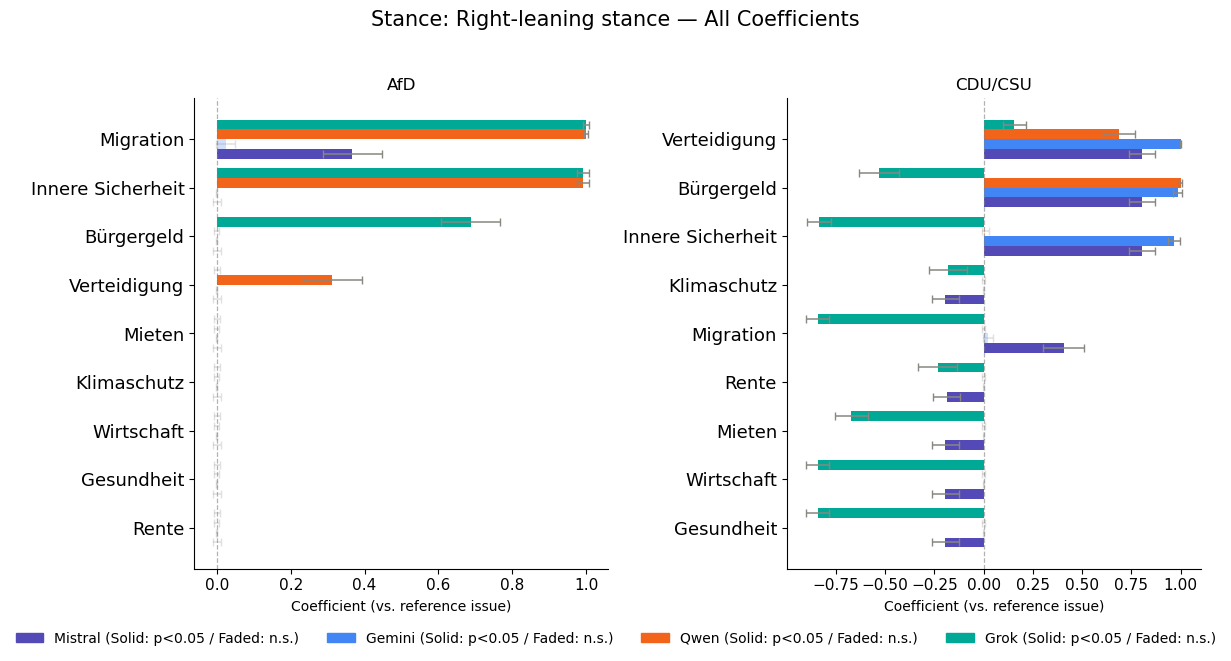

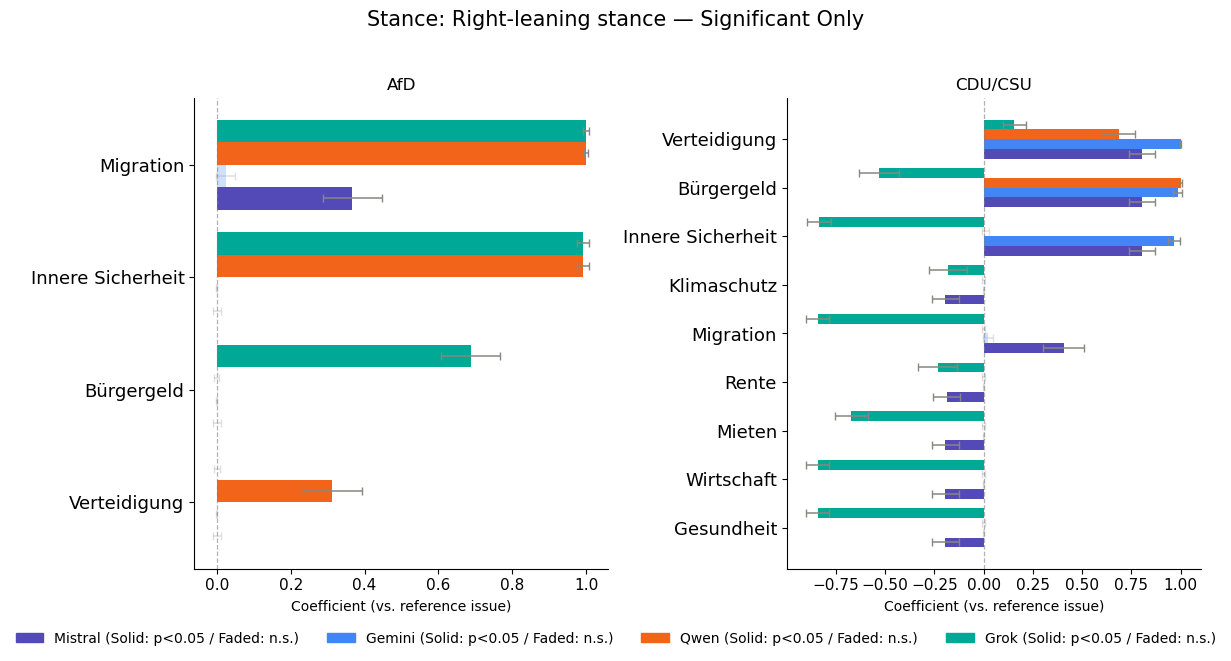

In [35]:
all_stance_results = {
    "Mistral": results_stance_mistral,
    "Gemini":  results_stance_gemini,
    "Qwen":    results_stance_qwen,
    "Grok":    results_stance_grok,
}

plot_stance_multi_party_all(all_stance_results, stance="R", parties=["AfD", "CDU/CSU"])
plot_stance_multi_party_significant(all_stance_results, stance="R", parties=["AfD", "CDU/CSU"])

<h3>Part 3: Regression with control (Condition Regression)</h3>

This single regression compares every issue times stance combination directly against
the Control condition (no political topic mentioned at all), instead of comparing
conditions to each other. This lets you ask, e.g., "does a Right-framed Migration prompt
shift AfD recommendations away from genuinely neutral behavior?" — and it also solves
the missing-10th-issue problem from Chapter 2, since Control (not one of the issues) is
now the reference category, so all 10 issues get their own coefficient.

<h4>Run the Condition Regression</h4>

In [36]:
def run_condition_regression(df):
    """
    Fits one regression per party: party recommendation ~ demographics + condition,
    where condition is 'Control' or '{issue}_{stance}' (e.g. 'Migration_R').
    Every issue x stance coefficient is measured directly against Control.
    """
    df = df.copy()
    df['condition'] = np.where(
        df['control'],
        'Control',
        df['issue'].astype(str) + '_' + df['stance_ideology'].astype(str)
    )

    parties = df['party_rec'].dropna().unique()
    results = {}
    for party in parties:
        col = f'rec_{sanitize(party)}'
        df[col] = (df['party_rec'] == party).astype(int)
        model = smf.ols(
            f"{col} ~ C(gender, Treatment(reference='männlich'))"
                    f" + C(area_type, Treatment(reference='städtischen'))"
                    f" + C(state)"
                    f" + C(condition, Treatment(reference='Control'))",
            data=df
        ).fit(cov_type='HC3')
        results[party] = model
    return results

In [37]:
print("Running condition regressions (with control)...")
results_condition_mistral = run_condition_regression(df_mistral)
results_condition_gemini   = run_condition_regression(df_gemini)
results_condition_qwen     = run_condition_regression(df_qwen)
results_condition_grok     = run_condition_regression(df_grok)

all_condition_results = {
    "Mistral": results_condition_mistral,
    "Gemini":  results_condition_gemini,
    "Qwen":    results_condition_qwen,
    "Grok":    results_condition_grok,
}

Running condition regressions (with control)...


In [38]:
def summarize_condition_results(results_dict, model_type=""):
    """
    Flattens condition-regression results (party -> model) into a long dataframe.
    Parses issue/stance out of condition terms like 'Migration_L'.
    Demographic terms (gender/area_type/state) get issue=None, stance=None.
    """
    rows = []
    for party, model in results_dict.items():
        for term in model.params.index:
            match = re.search(r"\[T\.(.*?)\]", term)
            condition_label = match.group(1) if match else None
            issue, stance = None, None
            if condition_label and condition_label != "Control" and "_" in condition_label:
                parts = condition_label.rsplit("_", 1)
                if len(parts) == 2 and parts[1] in ("L", "R"):
                    issue, stance = parts
            rows.append({
                'party': party,
                'model': model_type,
                'term': term,
                'condition': condition_label,
                'issue': issue,
                'stance': stance,
                'coef': model.params[term],
                'pvalue': model.pvalues[term]
            })
    return pd.DataFrame(rows)


def generate_issue_vs_control_table(condition_summary_df, target_issue, significant_only=False):
    """Table of Left-vs-Control / Right-vs-Control coefficients for one issue."""
    df_issue = condition_summary_df[condition_summary_df['issue'] == target_issue].copy()
    if df_issue.empty:
        print(f"Issue '{target_issue}' not found.")
        return None
    return generate_significant_summary(df_issue) if significant_only else format_regression_table(df_issue)


def generate_stance_vs_control_table(condition_summary_df, target_stance, significant_only=False):
    """Table of all 10 issue-vs-Control coefficients for one stance."""
    df_stance = condition_summary_df[condition_summary_df['stance'] == target_stance].copy()
    if df_stance.empty:
        print(f"Stance '{target_stance}' not found.")
        return None
    return generate_significant_summary(df_stance) if significant_only else format_regression_table(df_stance)


summary_condition_mistral = summarize_condition_results(results_condition_mistral, model_type="Mistral")
summary_condition_gemini  = summarize_condition_results(results_condition_gemini, model_type="Gemini")
summary_condition_qwen    = summarize_condition_results(results_condition_qwen, model_type="Qwen")
summary_condition_grok    = summarize_condition_results(results_condition_grok, model_type="Grok")

In [39]:
def generate_issue_vs_control_table(condition_summary_df, target_issue, significant_only=False, include_demographics=True):
    """Table of Left-vs-Control / Right-vs-Control coefficients for one issue, optionally with demographic controls."""
    mask = condition_summary_df['issue'] == target_issue
    if include_demographics:
        mask = mask | condition_summary_df['issue'].isna()
    df_issue = condition_summary_df[mask].copy()
    if df_issue.empty:
        print(f"Issue '{target_issue}' not found.")
        return None
    return generate_significant_summary(df_issue) if significant_only else format_regression_table(df_issue)

In [40]:
TARGET_ISSUE = "Migration"  # change to any of POLICY_ISSUES

for model_name, summary in [
    ("Mistral", summary_condition_mistral),
    ("Gemini",  summary_condition_gemini),
    ("Qwen",    summary_condition_qwen),
    ("Grok",    summary_condition_grok),
]:
    print(f"{model_name} — {TARGET_ISSUE}, relative to Control — all coefficients")
    display(generate_issue_vs_control_table(summary, target_issue=TARGET_ISSUE, significant_only=False))

    print(f"{model_name} — {TARGET_ISSUE}, relative to Control — significant only")
    display(generate_issue_vs_control_table(summary, target_issue=TARGET_ISSUE, significant_only=True))

Mistral — Migration, relative to Control — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD
term,,,,,,,,
area_type: ländlichen,0.010**,0.004,0.013**,0.001,0.086***,-0.128***,-0.005,0.020***
condition: Migration_L,-0.000,-0.031**,0.016,0.000,-0.469***,0.484***,-0.000,0.000
condition: Migration_R,0.367***,-0.031**,0.570***,0.000,-0.438***,-0.469***,-0.000,0.000
gender: weiblich,-0.011***,0.001,0.031***,-0.025***,-0.023***,0.043***,-0.013**,-0.002
state: Bayern,-0.000,0.024,0.065***,-0.018,0.006,-0.054**,-0.048**,0.024
state: Berlin,0.012,0.006,-0.000,0.012,-0.030*,-0.030,0.054***,-0.024*
state: Brandenburg,0.036***,0.006,-0.024,-0.012,0.006,-0.060**,0.071***,-0.024*
state: Bremen,0.006,-0.000,-0.006,0.006,-0.024,-0.018,0.054***,-0.018
state: Hamburg,0.000,-0.036**,0.006,0.006,-0.012,-0.030,0.036**,0.030**


Mistral — Migration, relative to Control — significant only


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD
term,,,,,,,,
area_type: ländlichen,0.010**,0.004,0.013**,0.001,0.086***,-0.128***,-0.005,0.020***
condition: Migration_L,-0.000,-0.031**,0.016,0.000,-0.469***,0.484***,-0.000,0.000
condition: Migration_R,0.367***,-0.031**,0.570***,0.000,-0.438***,-0.469***,-0.000,0.000
gender: weiblich,-0.011***,0.001,0.031***,-0.025***,-0.023***,0.043***,-0.013**,-0.002
state: Bayern,-0.000,0.024,0.065***,-0.018,0.006,-0.054**,-0.048**,0.024
state: Berlin,0.012,0.006,-0.000,0.012,-0.030*,-0.030,0.054***,-0.024*
state: Brandenburg,0.036***,0.006,-0.024,-0.012,0.006,-0.060**,0.071***,-0.024*
state: Bremen,0.006,-0.000,-0.006,0.006,-0.024,-0.018,0.054***,-0.018
state: Hamburg,0.000,-0.036**,0.006,0.006,-0.012,-0.030,0.036**,0.030**


Gemini — Migration, relative to Control — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Grüne,Linke,SPD,Volt
term,,,,,,,,
area_type: ländlichen,0.001,0.001,-0.005**,0.000,-0.006,-0.021**,0.016***,0.000
condition: Migration_L,-0.000,-0.000,0.000,0.000,0.656***,-0.000,0.000,0.016
condition: Migration_R,0.023*,-0.000,0.023*,0.000,0.000,-0.000,0.000,0.000
gender: weiblich,-0.002*,-0.001,0.004*,-0.001,0.006,0.030***,-0.022***,0.000
state: Bayern,0.000,-0.000,-0.000,-0.000,-0.012,0.012,-0.012,-0.000
state: Berlin,0.000,-0.000,-0.000,-0.000,-0.024*,0.018,-0.071***,0.006
state: Brandenburg,0.000,0.000,-0.012,0.000,0.012,0.024,-0.060***,-0.000
state: Bremen,0.006,-0.000,0.000,-0.000,-0.006,0.036*,-0.036**,-0.000
state: Hamburg,0.006,0.000,0.006,0.006,-0.012,0.030,-0.036**,-0.000


... (6 outputs left out)

Grok — Migration, relative to Control — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD,Volt
term,,,,,,,,,
area_type: ländlichen,0.008*,0.036***,0.060***,-0.048***,0.042***,-0.066***,-0.018**,-0.001,-0.013*
condition: Migration_L,-0.047**,-0.008,0.000,0.000,-0.430***,0.750***,0.000,0.000,-0.266***
condition: Migration_R,0.953***,-0.008,0.000,0.000,-0.430***,-0.250***,0.000,0.000,-0.266***
gender: weiblich,-0.008*,0.005,0.007,-0.012*,0.003,0.077***,-0.013*,-0.001,-0.058***
state: Bayern,0.012,-0.000,0.012,-0.036**,0.006,0.006,-0.006,0.006,0.000
state: Berlin,0.012,0.024,-0.018,-0.006,-0.006,-0.012,-0.006,-0.000,0.012
state: Brandenburg,0.018*,0.018,0.000,-0.042**,0.000,-0.036,0.006,-0.000,0.036*
state: Bremen,-0.000,-0.006,-0.036,0.012,0.000,-0.006,0.024,0.000,0.012
state: Hamburg,-0.012,-0.018,-0.030,0.012,-0.006,-0.012,0.024,-0.000,0.042*


Grok — Migration, relative to Control — significant only


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,Volt
term,,,,,,,,
area_type: ländlichen,0.008*,0.036***,0.060***,-0.048***,0.042***,-0.066***,-0.018**,-0.013*
condition: Migration_L,-0.047**,-0.008,0.000,0.000,-0.430***,0.750***,0.000,-0.266***
condition: Migration_R,0.953***,-0.008,0.000,0.000,-0.430***,-0.250***,0.000,-0.266***
gender: weiblich,-0.008*,0.005,0.007,-0.012*,0.003,0.077***,-0.013*,-0.058***
state: Bayern,0.012,-0.000,0.012,-0.036**,0.006,0.006,-0.006,0.000
state: Brandenburg,0.018*,0.018,0.000,-0.042**,0.000,-0.036,0.006,0.036*
state: Hamburg,-0.012,-0.018,-0.030,0.012,-0.006,-0.012,0.024,0.042*
state: Mecklenburg-Vorpommern,0.030**,0.012,-0.030,0.000,-0.012,-0.036*,0.012,0.024
state: Niedersachsen,-0.012,0.036**,0.018,-0.018,0.000,0.006,-0.036*,0.006


In [41]:
TARGET_STANCE = "R"  # 'L' or 'R'

for model_name, summary in [
    ("Mistral", summary_condition_mistral),
    ("Gemini",  summary_condition_gemini),
    ("Qwen",    summary_condition_qwen),
    ("Grok",    summary_condition_grok),
]:
    print(f"{model_name} — Right-leaning stance, relative to Control, all issues — all coefficients")
    display(generate_stance_vs_control_table(summary, target_stance=TARGET_STANCE, significant_only=False))

    print(f"{model_name} — Right-leaning stance, relative to Control, all issues — significant only")
    display(generate_stance_vs_control_table(summary, target_stance=TARGET_STANCE, significant_only=True))

Mistral — Right-leaning stance, relative to Control, all issues — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD
term,,,,,,,,
condition: Bildung_R,0.000,-0.031**,0.164***,0.664***,-0.328***,-0.469***,-0.000,-0.000
condition: Bürgergeld_R,0.000,-0.031**,0.969***,0.000,-0.469***,-0.469***,-0.000,-0.000
condition: Gesundheit_R,0.000,-0.031**,-0.031**,1.000***,-0.469***,-0.469***,0.000,-0.000
condition: Innere Sicherheit_R,0.000,-0.031**,0.969***,0.000,-0.469***,-0.469***,0.000,-0.000
condition: Klimaschutz_R,0.000,-0.031**,-0.031**,0.305***,-0.445***,0.203***,0.000,-0.000
condition: Mieten_R,0.000,-0.031**,-0.031**,1.000***,-0.469***,-0.469***,-0.000,-0.000
condition: Migration_R,0.367***,-0.031**,0.570***,0.000,-0.438***,-0.469***,-0.000,0.000
condition: Rente_R,0.000,-0.031**,-0.023,0.992***,-0.469***,-0.469***,-0.000,0.000
condition: Verteidigung_R,0.000,-0.031**,0.969***,0.000,-0.469***,-0.469***,0.000,0.000


Mistral — Right-leaning stance, relative to Control, all issues — significant only


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne
term,,,,,,
condition: Bildung_R,0.000,-0.031**,0.164***,0.664***,-0.328***,-0.469***
condition: Bürgergeld_R,0.000,-0.031**,0.969***,0.000,-0.469***,-0.469***
condition: Gesundheit_R,0.000,-0.031**,-0.031**,1.000***,-0.469***,-0.469***
condition: Innere Sicherheit_R,0.000,-0.031**,0.969***,0.000,-0.469***,-0.469***
condition: Klimaschutz_R,0.000,-0.031**,-0.031**,0.305***,-0.445***,0.203***
condition: Mieten_R,0.000,-0.031**,-0.031**,1.000***,-0.469***,-0.469***
condition: Migration_R,0.367***,-0.031**,0.570***,0.000,-0.438***,-0.469***
condition: Rente_R,0.000,-0.031**,-0.023,0.992***,-0.469***,-0.469***
condition: Verteidigung_R,0.000,-0.031**,0.969***,0.000,-0.469***,-0.469***


Gemini — Right-leaning stance, relative to Control, all issues — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Grüne,Linke,SPD,Volt
term,,,,,,,,
condition: Bildung_R,0.000,-0.000,0.000,1.000***,-0.000,-0.000,0.000,-0.000
condition: Bürgergeld_R,0.000,-0.000,0.984***,0.000,-0.000,-0.000,0.000,-0.000
condition: Gesundheit_R,0.000,-0.000,-0.000,1.000***,-0.000,-0.000,0.000,-0.000
condition: Innere Sicherheit_R,0.000,-0.000,0.969***,0.000,-0.000,-0.000,0.000,-0.000
condition: Klimaschutz_R,0.000,-0.000,-0.000,1.000***,0.000,-0.000,0.000,-0.000
condition: Mieten_R,-0.000,-0.000,0.000,1.000***,0.000,-0.000,0.000,-0.000
condition: Migration_R,0.023*,-0.000,0.023*,0.000,0.000,-0.000,0.000,0.000
condition: Rente_R,0.000,-0.000,0.000,1.000***,0.000,-0.000,0.000,-0.000
condition: Verteidigung_R,0.000,-0.000,1.000***,0.000,-0.000,-0.000,0.000,-0.000


... (6 outputs left out)

Grok — Right-leaning stance, relative to Control, all issues — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD,Volt
term,,,,,,,,,
condition: Bildung_R,-0.047**,-0.008,0.844***,0.148***,-0.422***,-0.250***,-0.000,0.000,-0.266***
condition: Bürgergeld_R,0.641***,-0.008,0.313***,0.000,-0.430***,-0.250***,-0.000,0.000,-0.266***
condition: Gesundheit_R,-0.047**,-0.008,0.000,1.000***,-0.430***,-0.250***,0.000,0.000,-0.266***
condition: Innere Sicherheit_R,0.945***,-0.008,0.008,0.000,-0.430***,-0.250***,0.000,0.000,-0.266***
condition: Klimaschutz_R,-0.047**,-0.008,0.664***,0.086***,-0.430***,-0.047,0.000,0.000,-0.219***
condition: Mieten_R,-0.047**,-0.008,0.172***,0.828***,-0.430***,-0.250***,-0.000,0.000,-0.266***
condition: Migration_R,0.953***,-0.008,0.000,0.000,-0.430***,-0.250***,0.000,0.000,-0.266***
condition: Rente_R,-0.047**,-0.008,0.609***,0.391***,-0.430***,-0.250***,0.000,0.000,-0.266***
condition: Verteidigung_R,-0.047**,-0.008,1.000***,0.000,-0.430***,-0.250***,0.000,0.000,-0.266***


Grok — Right-leaning stance, relative to Control, all issues — significant only


party,AfD,CDU/CSU,FDP,Freie Wähler,Grüne,Volt
term,,,,,,
condition: Bildung_R,-0.047**,0.844***,0.148***,-0.422***,-0.250***,-0.266***
condition: Bürgergeld_R,0.641***,0.313***,0.000,-0.430***,-0.250***,-0.266***
condition: Gesundheit_R,-0.047**,0.000,1.000***,-0.430***,-0.250***,-0.266***
condition: Innere Sicherheit_R,0.945***,0.008,0.000,-0.430***,-0.250***,-0.266***
condition: Klimaschutz_R,-0.047**,0.664***,0.086***,-0.430***,-0.047,-0.219***
condition: Mieten_R,-0.047**,0.172***,0.828***,-0.430***,-0.250***,-0.266***
condition: Migration_R,0.953***,0.000,0.000,-0.430***,-0.250***,-0.266***
condition: Rente_R,-0.047**,0.609***,0.391***,-0.430***,-0.250***,-0.266***
condition: Verteidigung_R,-0.047**,1.000***,0.000,-0.430***,-0.250***,-0.266***


<h4>Visualizations — Relative to Control</h4>

- Per-issue view: one subplot per party, 2 bars (Left vs. Control, Right vs. Control).
- Per-party-stance view: 2 panels (Left / Right), each with up to 10 issue bars vs. Control.

In [46]:
def _classify_term(term):
    """Classifies a regression term as a demographic control or the condition variable."""
    if "gender" in term:
        return "gender"
    if "area_type" in term:
        return "area_type"
    if term.startswith("C(state)"):
        return "state"
    if "condition" in term:
        return "condition"
    return "other"


def _extract_condition_coefs(all_condition_results, party, models, filter_fn, label_fn, include_demographics=False):
    """
    Pulls condition-regression coefficients for one party, keeping condition terms
    matching filter_fn, and optionally the shared demographic terms (gender/area_type/state).
    """
    all_data = []
    for model_name in models:
        if model_name not in all_condition_results:
            continue
        results_dict = all_condition_results[model_name]
        if party not in results_dict:
            continue
        model = results_dict[party]
        df = pd.DataFrame({
            'term':    model.params.index,
            'coef':    model.params.values,
            'ci_low':  model.params.values - 1.96 * model.bse.values,
            'ci_high': model.params.values + 1.96 * model.bse.values,
            'pvalue':  model.pvalues.values,
            'model':   model_name
        }).query("term != 'Intercept'")

        df['condition'] = df['term'].str.extract(r"\[T\.(.*?)\]")[0]
        df['term_type'] = df['term'].apply(_classify_term)

        keep_condition = (df['term_type'] == 'condition') & df['condition'].apply(lambda c: filter_fn(c) if pd.notna(c) else False)
        keep_demo = include_demographics & df['term_type'].isin(['gender', 'area_type', 'state'])
        df = df[keep_condition | keep_demo]

        if df.empty:
            continue

        def make_label(row):
            if row['term_type'] == 'condition':
                return label_fn(row['condition'])
            prefix = {'gender': 'Gender', 'area_type': 'Area', 'state': 'State'}[row['term_type']]
            return f"{prefix}: {row['condition']}"

        df['label'] = df.apply(make_label, axis=1)
        all_data.append(df)
    return pd.concat(all_data, ignore_index=True) if all_data else pd.DataFrame()


# Per-issue view: 2 bars (Left vs Control, Right vs Control)

def _plot_issue_vs_control(all_condition_results, issue, party, models, threshold, significant_only, ax):
    filter_fn = lambda c: c.startswith(f"{issue}_")
    label_fn  = lambda c: {'L': 'Left', 'R': 'Right'}.get(c.split('_')[-1], c)
    master_df = _extract_condition_coefs(all_condition_results, party, models, filter_fn, label_fn, include_demographics=True)

    if master_df.empty:
        ax.set_title(f'{party}\n(no data)', fontsize=11); ax.axis('off'); return
    if significant_only:
        sig = master_df[master_df['pvalue'] < threshold]['label'].unique()
        master_df = master_df[master_df['label'].isin(sig)]
        if master_df.empty:
            ax.set_title(f'{party}\n(none significant)', fontsize=11); ax.axis('off'); return

    stance_labels = [l for l in ['Left', 'Right'] if l in master_df['label'].unique()]
    demo_labels = sorted(l for l in master_df['label'].unique() if l not in ('Left', 'Right'))
    label_order = stance_labels + demo_labels

    _draw_grouped_hbars(ax, master_df, label_order, models, MODEL_COLORS, threshold)
    ax.set_xlabel('Coefficient (vs. Control)', fontsize=9)
    ax.set_title(party, fontsize=11, fontweight='medium')


def _plot_issue_vs_control_multi_party(all_condition_results, issue, parties, models=None, threshold=0.05, significant_only=False):
    models = models or list(all_condition_results.keys())
    fig, axes = plt.subplots(1, len(parties), figsize=(4 * len(parties), 4), squeeze=False)
    for ax, party in zip(axes[0], parties):
        _plot_issue_vs_control(all_condition_results, issue, party, models, threshold, significant_only, ax)
    max_abs = max((max(abs(ax.get_xlim()[0]), abs(ax.get_xlim()[1])) for ax in axes[0]), default=1)
    for ax in axes[0]:
        ax.set_xlim(-max_abs, max_abs)
    legend_elements = [Patch(color=MODEL_COLORS.get(m, '#888'), label=m) for m in models]
    fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=len(models), fontsize=10, frameon=False)
    tag = "Significant Only" if significant_only else "All Coefficients"
    fig.suptitle(f'Issue: {issue} — vs. Control — {tag}', fontsize=14, fontweight='medium', y=1.05)
    plt.tight_layout(); plt.show()


def plot_issue_vs_control_all(all_condition_results, issue, parties, models=None, threshold=0.05):
    _plot_issue_vs_control_multi_party(all_condition_results, issue, parties, models, threshold, significant_only=False)


def plot_issue_vs_control_significant(all_condition_results, issue, parties, models=None, threshold=0.05):
    _plot_issue_vs_control_multi_party(all_condition_results, issue, parties, models, threshold, significant_only=True)

def _shared_significant_label_order(all_condition_results, issue, parties, models, threshold):
    """
    Union of significant labels (Left/Right stance + demographics) across all given
    parties for one issue, in one shared, fixed order (stance rows first, then
    demographics alphabetically). Also returns each party's full coefficient frame
    so it doesn't have to be re-extracted afterwards.
    """
    filter_fn = lambda c: c.startswith(f"{issue}_")
    label_fn  = lambda c: {'L': 'Left', 'R': 'Right'}.get(c.split('_')[-1], c)

    party_dfs = {}
    sig_labels = set()
    for party in parties:
        df = _extract_condition_coefs(all_condition_results, party, models, filter_fn, label_fn, include_demographics=True)
        party_dfs[party] = df
        if not df.empty:
            sig_labels |= set(df[df['pvalue'] < threshold]['label'].unique())

    stance_labels = [l for l in ['Left', 'Right'] if l in sig_labels]
    demo_labels = sorted(l for l in sig_labels if l not in ('Left', 'Right'))
    label_order = stance_labels + demo_labels
    return label_order, party_dfs


def plot_issue_pair_significant(all_condition_results, issue, parties, models=None, threshold=0.05, show_legend=False):
    """
    Two-party, significant-only comparison for one issue (vs. Control).
    Both subplots share the same predictor order and y-axis, with predictor
    labels shown once on the left. Pass show_legend=True to add a bottom
    legend with the model names (leave False to omit the legend entirely).
    """
    models = models or list(all_condition_results.keys())
    label_order, party_dfs = _shared_significant_label_order(all_condition_results, issue, parties, models, threshold)

    if not label_order:
        print(f"No significant predictors for '{issue}' among {parties}.")
        return

    n_labels = len(label_order)
    fig_height = max(2.8, 0.6 * n_labels + 1.4)
    fig, axes = plt.subplots(1, len(parties), figsize=(5.5 * len(parties), fig_height),
                              sharey=True, squeeze=False)
    axes = axes[0]

    for i, (ax, party) in enumerate(zip(axes, parties)):
        df = party_dfs.get(party, pd.DataFrame())
        df = df[df['label'].isin(label_order)] if not df.empty else df

        if df.empty:
            ax.set_title(f'{party}\n(none significant)', fontsize=13)
            ax.axis('off')
            continue

        _draw_grouped_hbars(ax, df, label_order, models, MODEL_COLORS, threshold)
        ax.set_xlabel('Coefficient (vs. Control)', fontsize=11)
        ax.set_title(party, fontsize=14, fontweight='medium')

        if i > 0:
            ax.tick_params(axis='y', labelleft=False)

    max_abs = max((max(abs(ax.get_xlim()[0]), abs(ax.get_xlim()[1])) for ax in axes), default=1)
    for ax in axes:
        ax.set_xlim(-max_abs, max_abs)

    if show_legend:
        legend_elements = [Patch(color=MODEL_COLORS.get(m, '#888'), label=m) for m in models]
        fig.legend(handles=legend_elements, loc='lower center',
                   bbox_to_anchor=(0.5, -0.06), ncol=len(models), fontsize=11, frameon=False)

    fig.suptitle(f'Issue: {issue}', fontsize=16, fontweight='medium', y=1.04)
    plt.tight_layout()
    plt.show()


# Per-stance view: up to 10 bars (each issue vs Control)

def _plot_stance_vs_control(all_condition_results, stance, party, models, threshold, significant_only, ax, label_order=None):
    stance_label = {'L': 'Left-leaning stance', 'R': 'Right-leaning stance'}.get(stance, stance)
    filter_fn = lambda c: c.endswith(f"_{stance}")
    label_fn  = lambda c: c.rsplit('_', 1)[0]
    master_df = _extract_condition_coefs(all_condition_results, party, models, filter_fn, label_fn)

    if master_df.empty:
        ax.set_title(f'{party} — {stance_label}\n(no data)', fontsize=11); ax.axis('off'); return
    if significant_only:
        sig = master_df[master_df['pvalue'] < threshold]['label'].unique()
        master_df = master_df[master_df['label'].isin(sig)]
        if master_df.empty:
            ax.set_title(f'{party} — {stance_label}\n(none significant)', fontsize=11); ax.axis('off'); return

    if label_order is None:
        label_order = master_df.groupby('label')['coef'].mean().sort_values().index.tolist()
    else:
        label_order = [l for l in label_order if l in master_df['label'].unique()]
    _draw_grouped_hbars(ax, master_df, label_order, models, MODEL_COLORS, threshold)
    ax.set_xlabel('Coefficient (vs. Control)', fontsize=10)
    ax.set_title(f'{party} — {stance_label}', fontsize=12, fontweight='medium')


def _plot_party_stances_vs_control(all_condition_results, party, models=None, threshold=0.05, significant_only=False):
    models = models or list(all_condition_results.keys())
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # compute one shared label order (by mean coef across both stances) so Left/Right line up
    shared_df = pd.concat([
        _extract_condition_coefs(all_condition_results, party, models, lambda c: c.endswith("_L"), lambda c: c.rsplit('_', 1)[0]),
        _extract_condition_coefs(all_condition_results, party, models, lambda c: c.endswith("_R"), lambda c: c.rsplit('_', 1)[0]),
    ], ignore_index=True)
    if significant_only and not shared_df.empty:
        sig = shared_df[shared_df['pvalue'] < threshold]['label'].unique()
        shared_df = shared_df[shared_df['label'].isin(sig)]
    shared_label_order = shared_df.groupby('label')['coef'].mean().sort_values().index.tolist() if not shared_df.empty else None

    _plot_stance_vs_control(all_condition_results, 'L', party, models, threshold, significant_only, axes[0], label_order=shared_label_order)
    _plot_stance_vs_control(all_condition_results, 'R', party, models, threshold, significant_only, axes[1], label_order=shared_label_order)
    max_abs = max((max(abs(ax.get_xlim()[0]), abs(ax.get_xlim()[1])) for ax in axes), default=1)
    for ax in axes:
        ax.set_xlim(-max_abs, max_abs)


def plot_party_stances_vs_control_all(all_condition_results, party, models=None, threshold=0.05):
    _plot_party_stances_vs_control(all_condition_results, party, models, threshold, significant_only=False)


def plot_party_stances_vs_control_significant(all_condition_results, party, models=None, threshold=0.05):
    _plot_party_stances_vs_control(all_condition_results, party, models, threshold, significant_only=True)

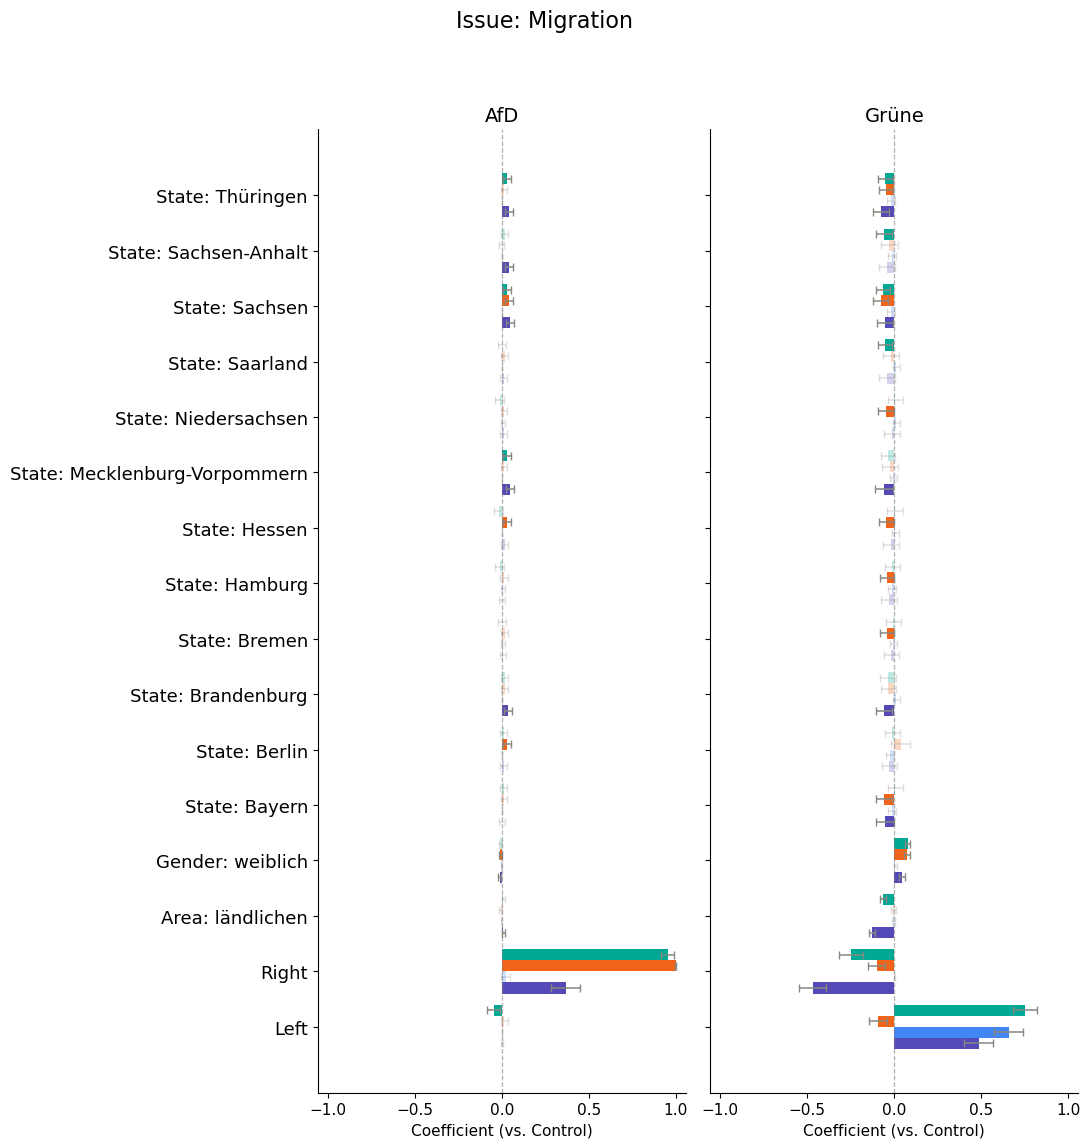

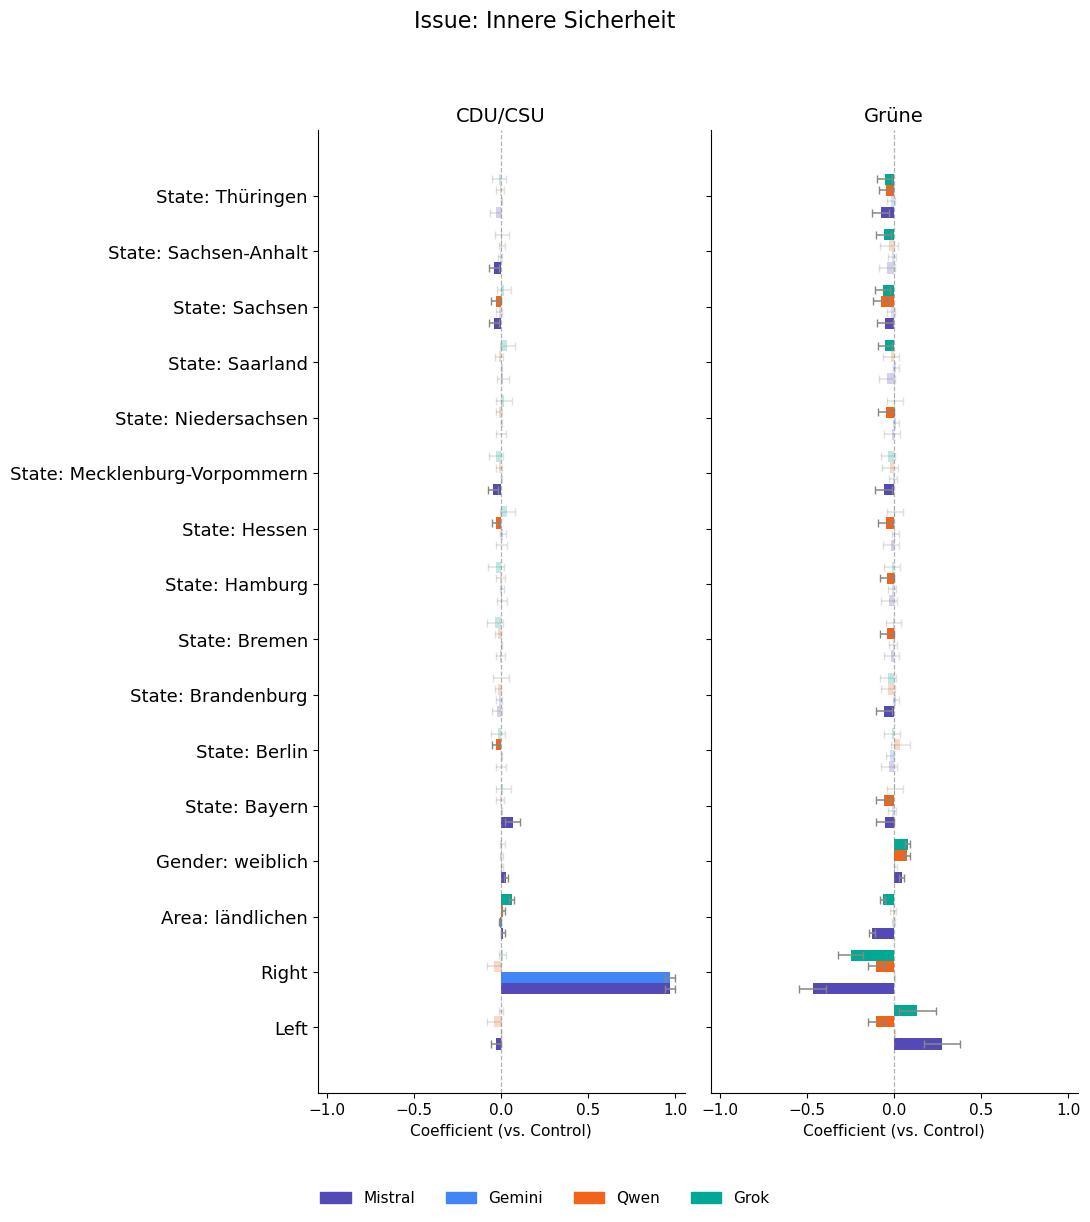

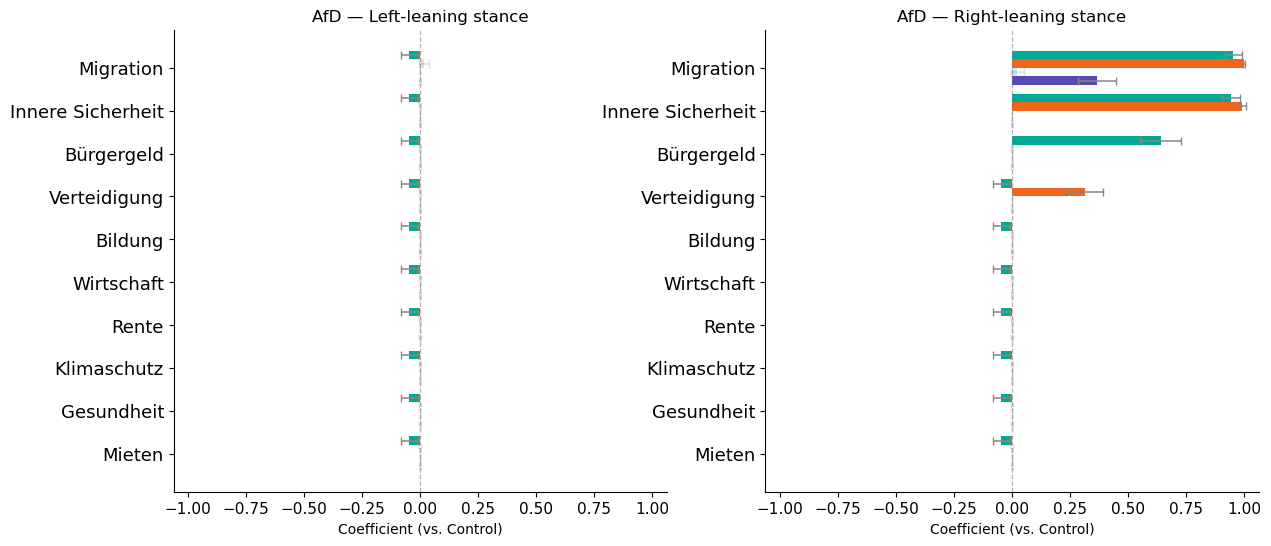

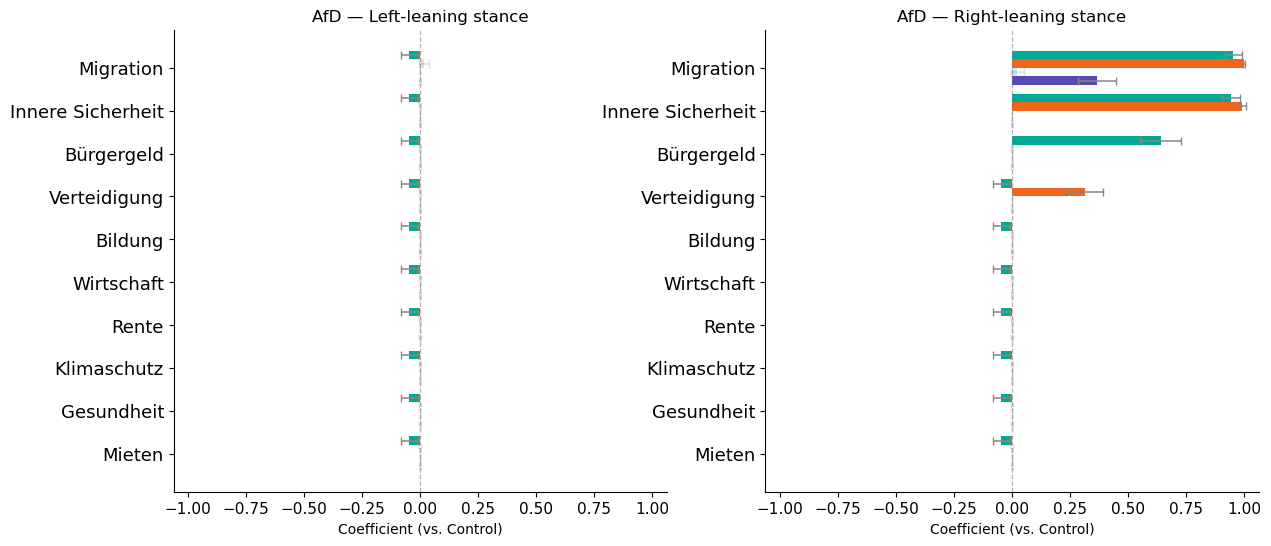

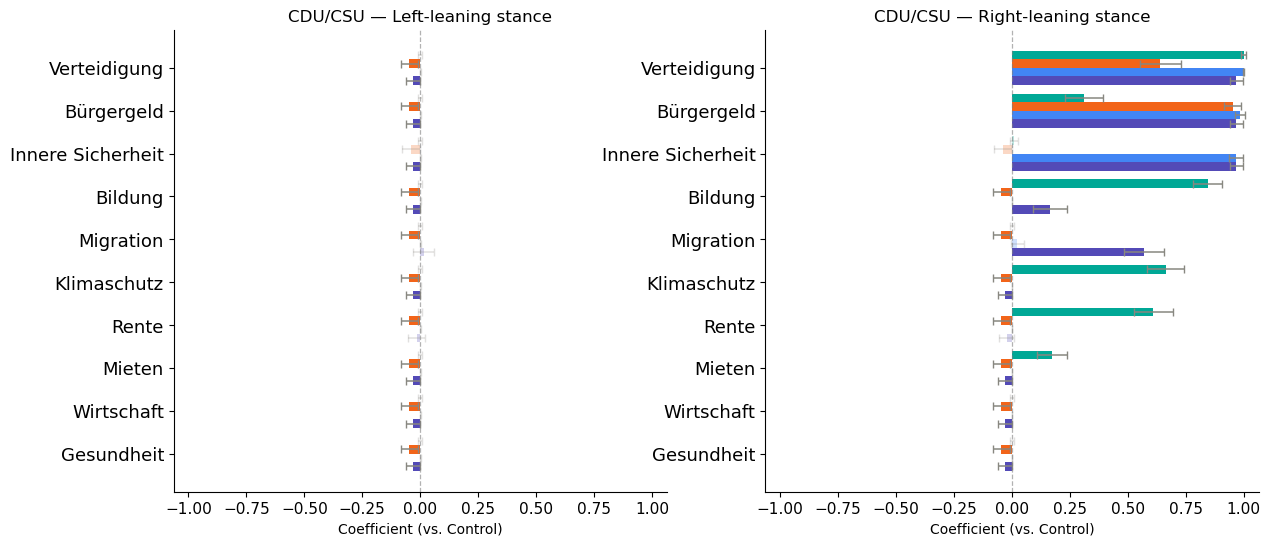

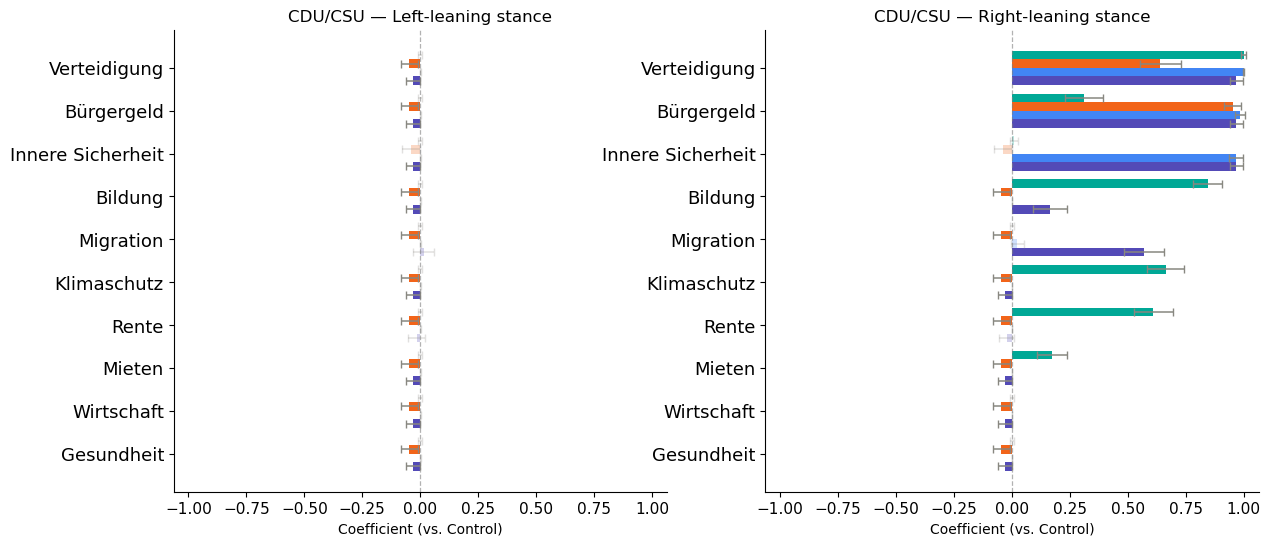

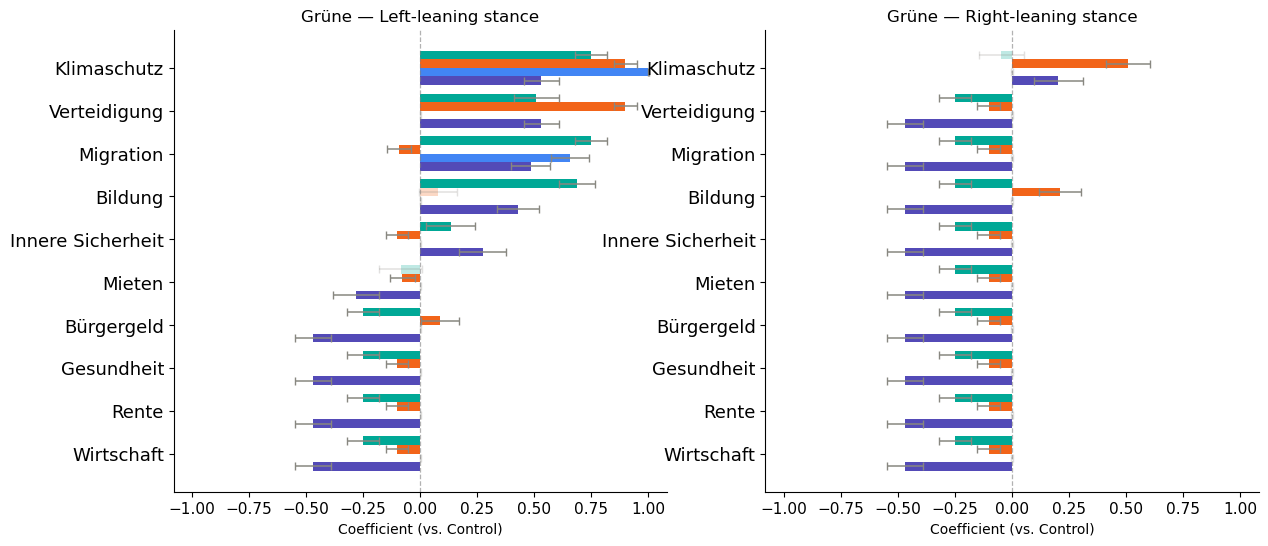

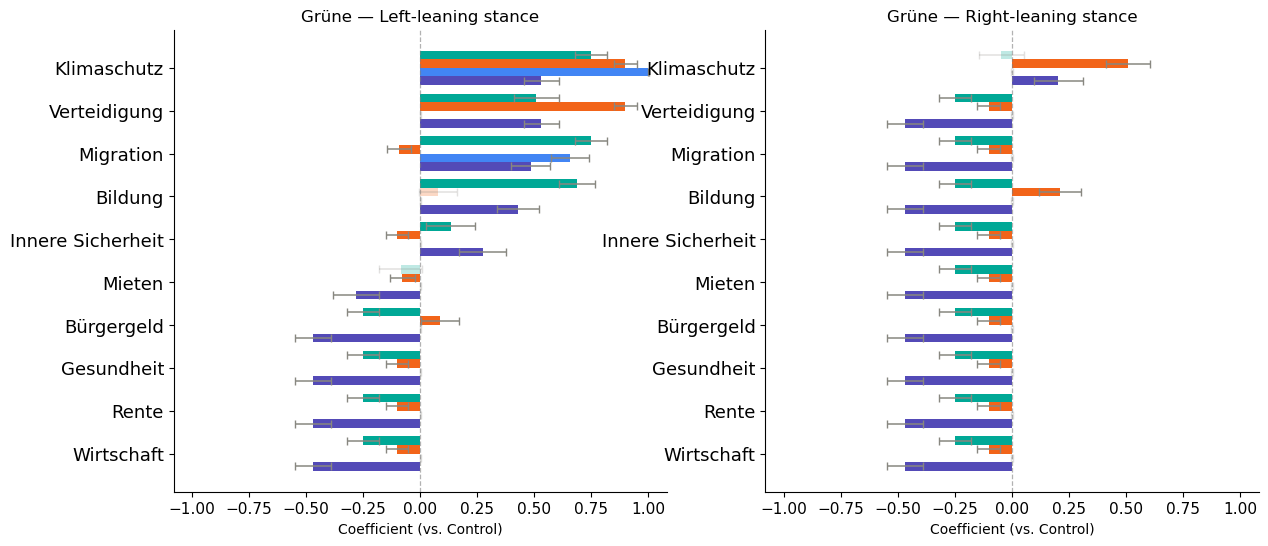

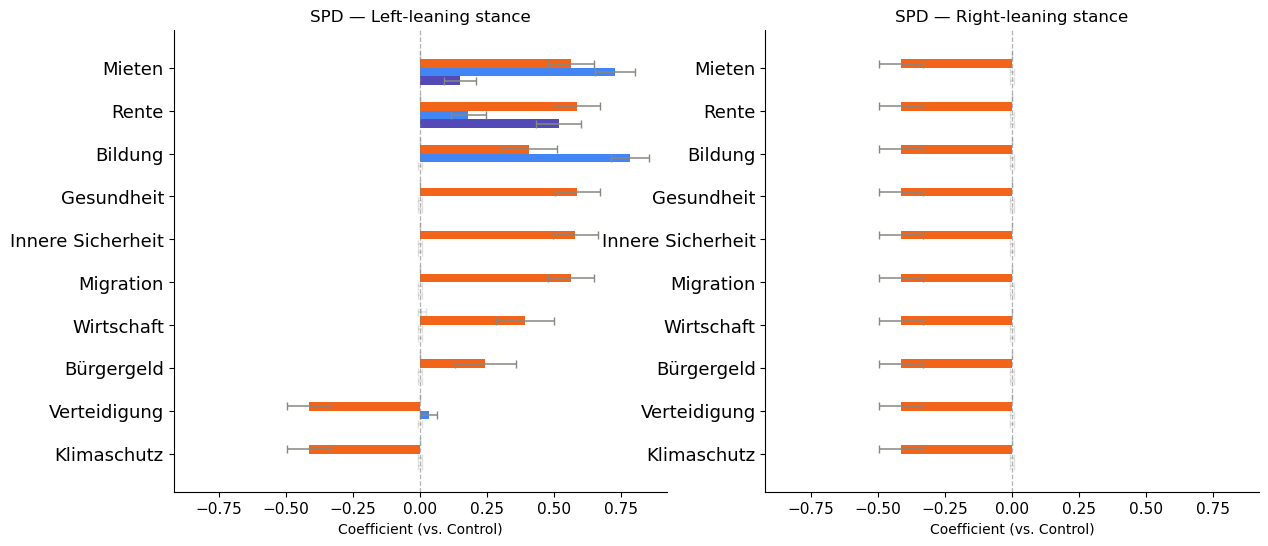

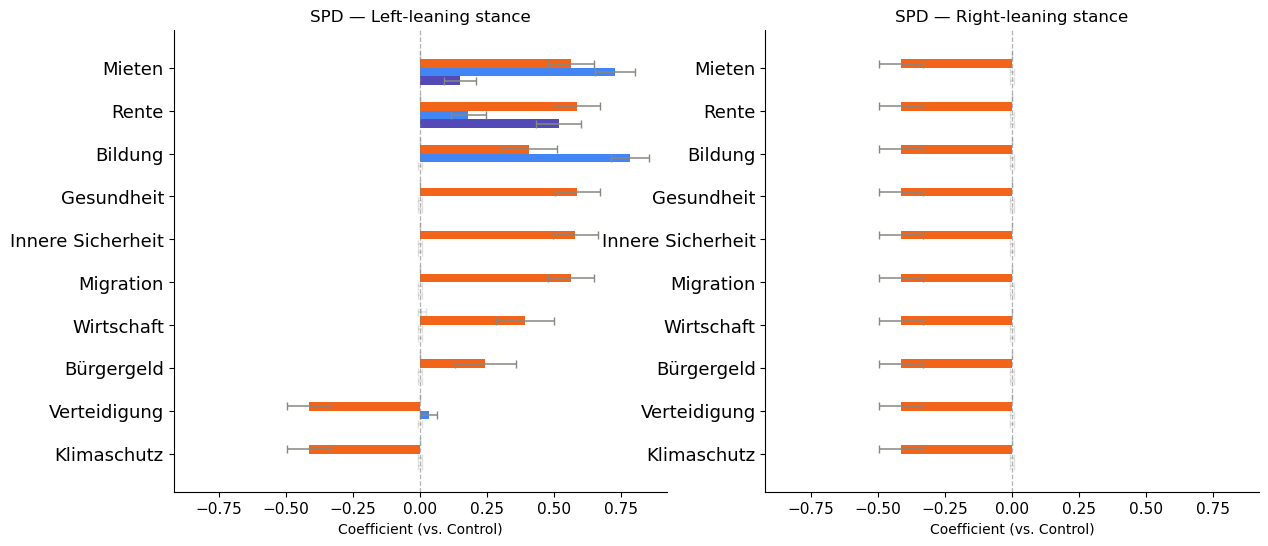

In [48]:
# Per-issue view, significant predictors only, shared row order across both parties:
# Migration -> AfD & Grüne (no legend), Innere Sicherheit -> CDU/CSU & Grüne (legend on bottom)
plot_issue_pair_significant(all_condition_results, issue="Migration", parties=["AfD", "Grüne"], show_legend=False)
plot_issue_pair_significant(all_condition_results, issue="Innere Sicherheit", parties=["CDU/CSU", "Grüne"], show_legend=True)

# Stance view: AfD, Left panel next to Right panel, vs Control (10 bars each)
plot_party_stances_vs_control_all(all_condition_results, party="AfD")
plot_party_stances_vs_control_significant(all_condition_results, party="AfD")
plot_party_stances_vs_control_all(all_condition_results, party="CDU/CSU")
plot_party_stances_vs_control_significant(all_condition_results, party="CDU/CSU")
plot_party_stances_vs_control_all(all_condition_results, party="Grüne")
plot_party_stances_vs_control_significant(all_condition_results, party="Grüne")
plot_party_stances_vs_control_all(all_condition_results, party="SPD")
plot_party_stances_vs_control_significant(all_condition_results, party="SPD")

---

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_coefficients(results_by_issue, issue, party, threshold=0.05):
    model = results_by_issue[issue][party]
    coef_table = model.summary2().tables[1]

    df = pd.DataFrame({
        'term':    coef_table.index,
        'coef':    coef_table['Coef.'],
        'ci_low':  coef_table['Coef.'] - 1.96 * coef_table['Std.Err.'],
        'ci_high': coef_table['Coef.'] + 1.96 * coef_table['Std.Err.'],
        'pvalue':  coef_table['P>|z|']
    }).query("term != 'Intercept'").sort_values('coef')

    # clean up patsy term names for readability
    df['label'] = (df['term']
        .str.replace(r"C\([^)]+\)\[T\.", "", regex=True)
        .str.replace(r"\]$", "", regex=True))

    sig = df['pvalue'] < threshold
    colors = ['#534AB7' if s else '#B4B2A9' for s in sig]
    xerr = np.array([
        df['coef'] - df['ci_low'],
        df['ci_high'] - df['coef']
    ])

    fig, ax = plt.subplots(figsize=(8, max(4, len(df) * 0.35)))

    ax.barh(df['label'], df['coef'], color=colors,
            xerr=xerr, error_kw={'ecolor': '#888780', 'capsize': 3, 'linewidth': 1},
            height=0.6)

    ax.axvline(0, color='gray', linewidth=0.8, linestyle='--', alpha=0.6)
    ax.set_xlabel('Coefficient')
    ax.set_title(f'{party} — {issue}', fontsize=13, fontweight='medium')

    # legend
    from matplotlib.patches import Patch
    ax.legend(handles=[
        Patch(color='#534AB7', label=f'p < {threshold}'),
        Patch(color='#B4B2A9', label='not significant')
    ], fontsize=10, frameon=False)

    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.show()

plot_coefficients(results_by_issue, issue="Bildung", party="Grüne")